Seleção de colunas e PCA

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from IPython.display import display
from sklearn.model_selection import TimeSeriesSplit
import time
import psutil
import os
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

tscv = TimeSeriesSplit(n_splits=5)

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', None)

df = pd.read_csv("./raw/dataset_merged_binary.csv", parse_dates=["date"])

cols = ["date", "credit_spread", "credit_spread_diff", "industrial_production", "industrial_production_mom", "industrial_production_yoy", "price_index", "inflation_mom",
    "inflation_yoy", "real_interest", "real_interest_diff", "volatility_index", "volatility_index_mom", "yield_curve_slope", "yield_curve_slope_diff", "target_12m"]

df = df[cols].dropna().reset_index(drop=True)

features = ["credit_spread", "credit_spread_diff", "industrial_production", "industrial_production_mom", "industrial_production_yoy", "price_index", "inflation_mom",
    "inflation_yoy", "real_interest", "real_interest_diff", "volatility_index", "volatility_index_mom", "yield_curve_slope", "yield_curve_slope_diff"]

Matriz de Correlação

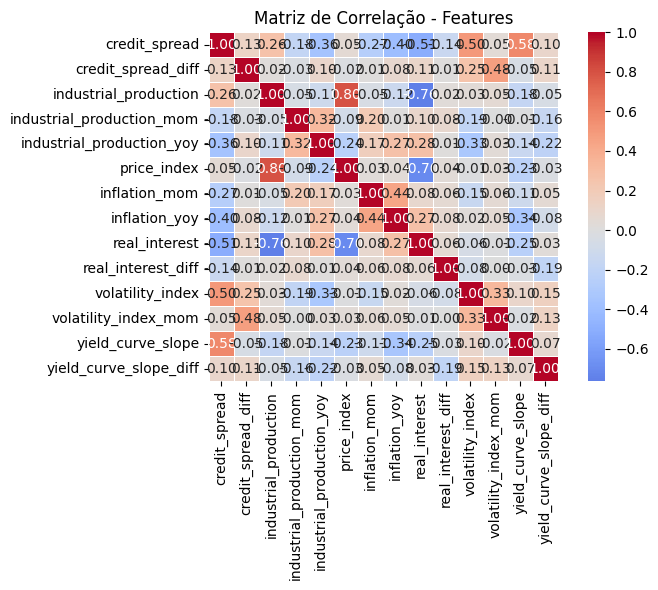

Matriz de Correlação:
                           credit_spread  credit_spread_diff  industrial_production  industrial_production_mom  industrial_production_yoy  price_index  inflation_mom  inflation_yoy  real_interest  real_interest_diff  volatility_index  volatility_index_mom  yield_curve_slope  yield_curve_slope_diff
credit_spread                   1.000000            0.130974               0.261203                  -0.182236                  -0.358902     0.050529      -0.265613      -0.404380      -0.514573           -0.138257          0.497201              0.045053           0.578270                0.102934
credit_spread_diff              0.130974            1.000000               0.016354                  -0.026486                   0.100941    -0.017295       0.008910       0.078325       0.106229            0.009533          0.254145              0.475916          -0.049492                0.108439
industrial_production           0.261203            0.016354               1.0000

In [45]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df[features].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5
)
plt.title("Matriz de Correlação - Features")
plt.tight_layout()
plt.show()

print("Matriz de Correlação:")
print(corr.to_string())

Divisão entre treino e teste

In [46]:
from sklearn.model_selection import train_test_split

# Ordena cronologicamente
df = df.sort_values("date").reset_index(drop=True)

X = df[features]
y = df["target_12m"]

# ==========================
# Divisão treino / teste
# ==========================

X_train_no_pca, X_test_no_pca, y_train_no_pca, y_test_no_pca = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    shuffle=False
)

# ==========================
# StandardScaler
# ==========================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_no_pca)
X_test_scaled = scaler.transform(X_test_no_pca)

# ==========================
# PCA
# ==========================

pca = PCA(n_components=3)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# ==========================
# Variância explicada
# ==========================

variancia_explicada = pca.explained_variance_ratio_
variancia_total = variancia_explicada.sum()

print(f"Variância explicada pela PC1: {variancia_explicada[0]:.2%}")
print(f"Variância explicada pela PC2: {variancia_explicada[1]:.2%}")
print(f"Variância explicada pela PC3: {variancia_explicada[2]:.2%}")
print(f"Variância total explicada: {variancia_total:.2%}")

# ==========================
# DataFrames PCA (mantidos)
# ==========================

X_train_pca = pd.DataFrame(
    X_train_pca,
    columns=["pca_1", "pca_2", "pca_3"],
    index=X_train_no_pca.index
)

X_test_pca = pd.DataFrame(
    X_test_pca,
    columns=["pca_1", "pca_2", "pca_3"],
    index=X_test_no_pca.index
)

# Targets para os modelos com PCA
y_train_pca = y_train_no_pca.copy()
y_test_pca = y_test_no_pca.copy()

Variância explicada pela PC1: 29.02%
Variância explicada pela PC2: 14.79%
Variância explicada pela PC3: 10.83%
Variância total explicada: 54.64%


Função base de treino, teste e plot dos modelos

In [47]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    accuracy_score,
    precision_score,
    recall_score
)

import matplotlib.pyplot as plt
import pandas as pd

LABELS = ["Normal", "Crise"]
ALL_CLASSES = [0, 1]

resultados = []

def avaliar_modelo(
    model,
    X_train,
    X_test,
    y_train,
    y_test,
    nome_modelo="Modelo",
    tempo_treino=None,
    tempo_predicao=None,
    memoria_mb=None
):

    print(f"\n===== {nome_modelo} =====")

    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    print("\n--- TREINO ---")
    print(
        classification_report(
            y_train,
            y_pred_train,
            labels=ALL_CLASSES,
            target_names=LABELS,
            zero_division=0
        )
    )

    print("\n--- TESTE ---")
    print(
        classification_report(
            y_test,
            y_pred_test,
            labels=ALL_CLASSES,
            target_names=LABELS,
            zero_division=0
        )
    )

    # ===== INFORMAÇÕES COMPUTACIONAIS =====

    if tempo_treino is not None:
        print(f"\nTempo de treino: {tempo_treino:.4f} s")

    if tempo_predicao is not None:
        print(f"Tempo de predição: {tempo_predicao * 1000:.4f} ms")

    if memoria_mb is not None:
        print(f"Memória utilizada: {memoria_mb:.2f} MB")

    # ===== ACUMULA RESULTADOS =====
    resultados.append({
        "modelo": nome_modelo,
        "accuracy": accuracy_score(y_test, y_pred_test),
        "precision": precision_score(
            y_test,
            y_pred_test,
            average="macro",
            labels=ALL_CLASSES,
            zero_division=0
        ),
        "recall": recall_score(
            y_test,
            y_pred_test,
            average="macro",
            labels=ALL_CLASSES,
            zero_division=0
        ),
        "f1_macro": f1_score(
            y_test,
            y_pred_test,
            average="macro",
            labels=ALL_CLASSES,
            zero_division=0
        ),
        "tempo_treino_s": tempo_treino
    })

    # ===== MATRIZES DE CONFUSÃO =====

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    cm_train = confusion_matrix(
        y_train,
        y_pred_train,
        labels=ALL_CLASSES
    )

    ConfusionMatrixDisplay(
        cm_train,
        display_labels=LABELS
    ).plot(
        ax=axes[0],
        xticks_rotation=45,
        cmap="Reds"
    )

    axes[0].set_title(
        f"{nome_modelo} - Matriz de Confusão (Treino)"
    )

    cm_test = confusion_matrix(
        y_test,
        y_pred_test,
        labels=ALL_CLASSES
    )

    ConfusionMatrixDisplay(
        cm_test,
        display_labels=LABELS
    ).plot(
        ax=axes[1],
        xticks_rotation=45,
        cmap="Reds"
    )

    axes[1].set_title(
        f"{nome_modelo} - Matriz de Confusão (Teste)"
    )

    plt.tight_layout()
    plt.show()

Árvore de Decisão

Melhores parâmetros (sem PCA):
{'ccp_alpha': 0.0, 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}

===== Decision Tree (sem PCA) =====

--- TREINO ---
              precision    recall  f1-score   support

      Normal       0.93      0.93      0.93       147
       Crise       0.94      0.93      0.93       157

    accuracy                           0.93       304
   macro avg       0.93      0.93      0.93       304
weighted avg       0.93      0.93      0.93       304


--- TESTE ---
              precision    recall  f1-score   support

      Normal       0.76      0.59      0.67        91
       Crise       0.38      0.57      0.46        40

    accuracy                           0.59       131
   macro avg       0.57      0.58      0.56       131
weighted avg       0.65      0.59      0.60       131


Tempo de treino: 42.2024 s
Tempo de predição: 0.0000 ms
Memória utilizada: 499.20 MB


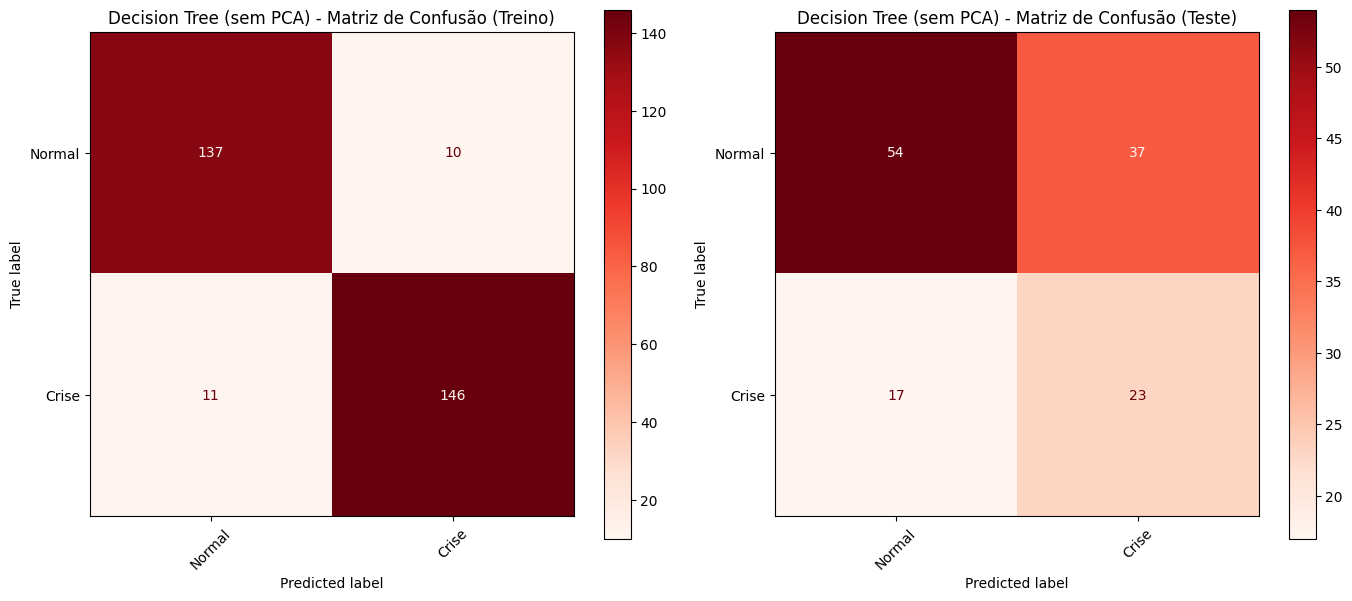

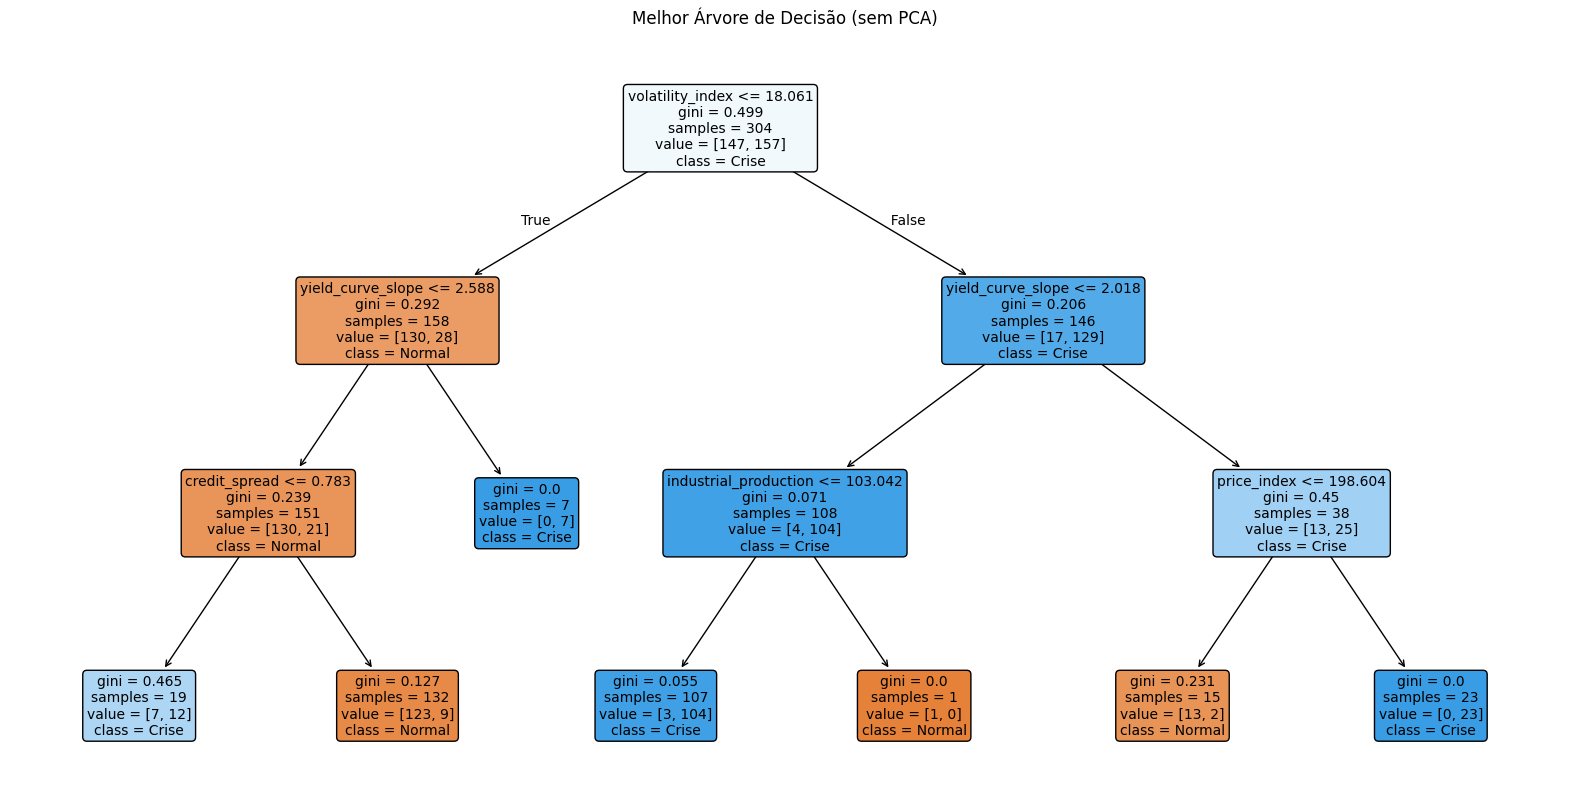

Melhores parâmetros (PCA):
{'ccp_alpha': 0.0, 'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 2}

===== Decision Tree (PCA) =====

--- TREINO ---
              precision    recall  f1-score   support

      Normal       0.77      0.67      0.72       147
       Crise       0.73      0.81      0.77       157

    accuracy                           0.74       304
   macro avg       0.75      0.74      0.74       304
weighted avg       0.75      0.74      0.74       304


--- TESTE ---
              precision    recall  f1-score   support

      Normal       0.71      0.56      0.63        91
       Crise       0.32      0.47      0.38        40

    accuracy                           0.53       131
   macro avg       0.52      0.52      0.50       131
weighted avg       0.59      0.53      0.55       131


Tempo de treino: 1.2802 s
Tempo de predição: 14.5819 ms
Memória utilizada: 507.17 MB


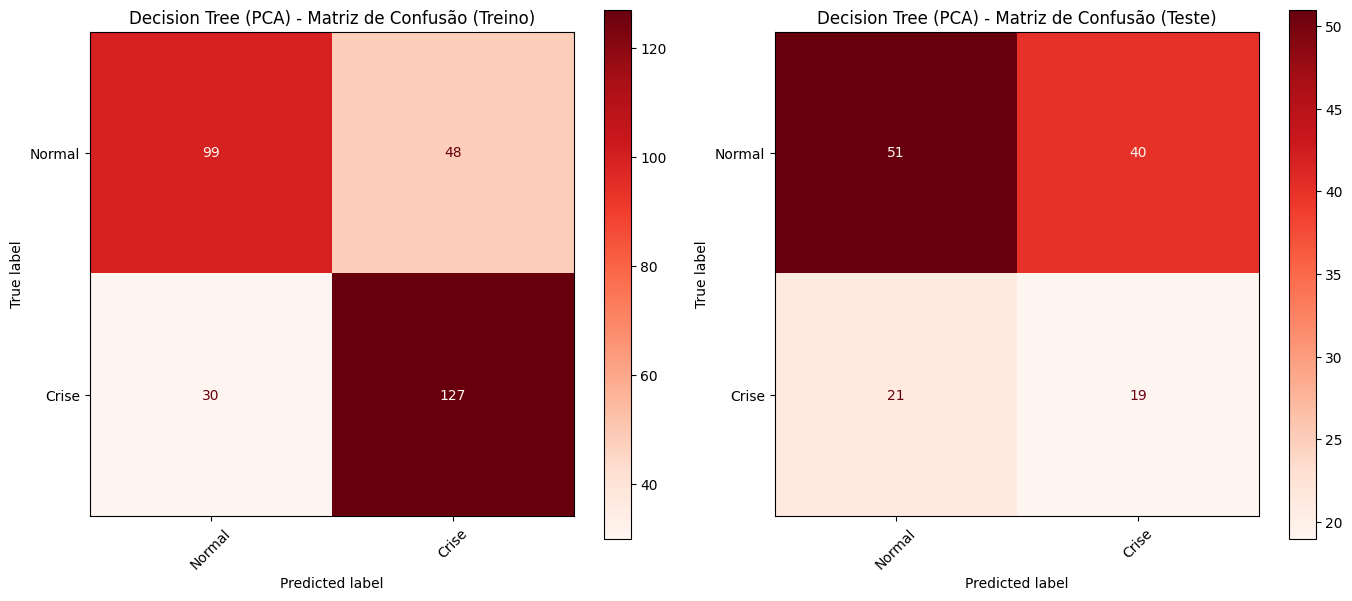

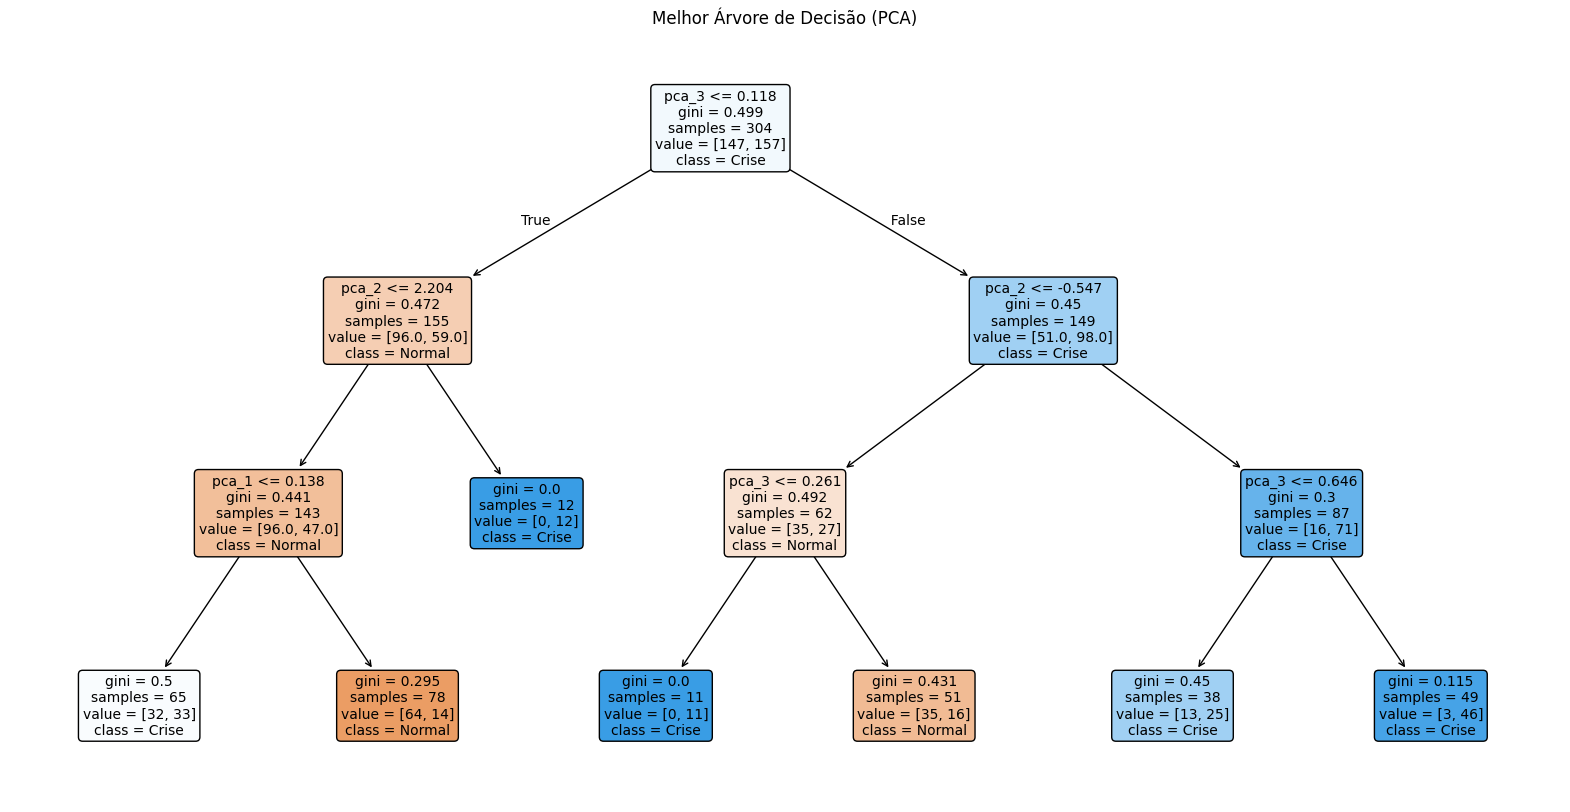

In [48]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt

# ===== GRID DE HIPERPARÂMETROS =====
param_grid = {
    "max_depth": [3, 5, 7, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "ccp_alpha": [0.0, 0.001, 0.005]
}

# ===== MODELO BASE =====
tree = DecisionTreeClassifier(random_state=42)

# TREINAR SEM PCA
grid_no_pca = GridSearchCV(
    tree,
    param_grid,
    cv=tscv,
    scoring="f1_macro",
    n_jobs=-1
)

inicio_treino = time.time()

grid_no_pca.fit(X_train_no_pca, y_train_no_pca)

tempo_treino = time.time() - inicio_treino

best_tree_no_pca = grid_no_pca.best_estimator_

processo = psutil.Process(os.getpid())
memoria_mb = processo.memory_info().rss / 1024 / 1024

inicio_predicao = time.time()

best_tree_no_pca.predict(X_test_no_pca)

tempo_predicao = time.time() - inicio_predicao

print("Melhores parâmetros (sem PCA):")
print(grid_no_pca.best_params_)

avaliar_modelo(
    best_tree_no_pca,
    X_train_no_pca,
    X_test_no_pca,
    y_train_no_pca,
    y_test_no_pca,
    nome_modelo="Decision Tree (sem PCA)",
    tempo_treino=tempo_treino,
    tempo_predicao=tempo_predicao,
    memoria_mb=memoria_mb
)

plt.figure(figsize=(20, 10))
plot_tree(
    best_tree_no_pca,
    feature_names=features,
    class_names=LABELS,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Melhor Árvore de Decisão (sem PCA)")
plt.show()

# TREINAR COM PCA
grid_pca = GridSearchCV(
    tree,
    param_grid,
    cv=tscv,
    scoring="f1_macro",
    n_jobs=-1
)

inicio_treino = time.time()

grid_pca.fit(X_train_pca, y_train_pca)

tempo_treino = time.time() - inicio_treino

best_tree_pca = grid_pca.best_estimator_

processo = psutil.Process(os.getpid())
memoria_mb = processo.memory_info().rss / 1024 / 1024

inicio_predicao = time.time()

best_tree_pca.predict(X_test_pca)

tempo_predicao = time.time() - inicio_predicao

print("Melhores parâmetros (PCA):")
print(grid_pca.best_params_)

avaliar_modelo(
    best_tree_pca,
    X_train_pca,
    X_test_pca,
    y_train_pca,
    y_test_pca,
    nome_modelo="Decision Tree (PCA)",
    tempo_treino=tempo_treino,
    tempo_predicao=tempo_predicao,
    memoria_mb=memoria_mb
)

plt.figure(figsize=(20, 10))
plot_tree(
    best_tree_pca,
    feature_names=["pca_1", "pca_2", "pca_3"],
    class_names=LABELS,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Melhor Árvore de Decisão (PCA)")
plt.show()

Árvore de Decisão - Curvas de validação e desempenho por fold

Melhores parâmetros (sem PCA): {'ccp_alpha': 0.0, 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
F1 macro médio na validação: 0.3090

Top 10 configurações (sem PCA):


,rank_test_score,ccp_alpha,max_depth,min_samples_leaf,min_samples_split,mean_train_score,mean_test_score,std_test_score,gap_treino_val
0,1,0.0,3,1,2,0.9778,0.309,0.0987,0.6689
1,1,0.0,3,1,5,0.9778,0.309,0.0987,0.6689
2,1,0.0,3,1,10,0.9778,0.309,0.0987,0.6689
3,1,0.0,3,2,2,0.9747,0.309,0.0987,0.6658
4,1,0.0,3,2,5,0.9747,0.309,0.0987,0.6658
5,1,0.0,3,2,10,0.9747,0.309,0.0987,0.6658
6,1,0.0,3,4,2,0.9693,0.309,0.0987,0.6604
7,1,0.0,3,4,5,0.9693,0.309,0.0987,0.6604
8,1,0.0,3,4,10,0.9693,0.309,0.0987,0.6604
9,1,0.0,5,1,2,1.0000,0.309,0.0987,0.6910


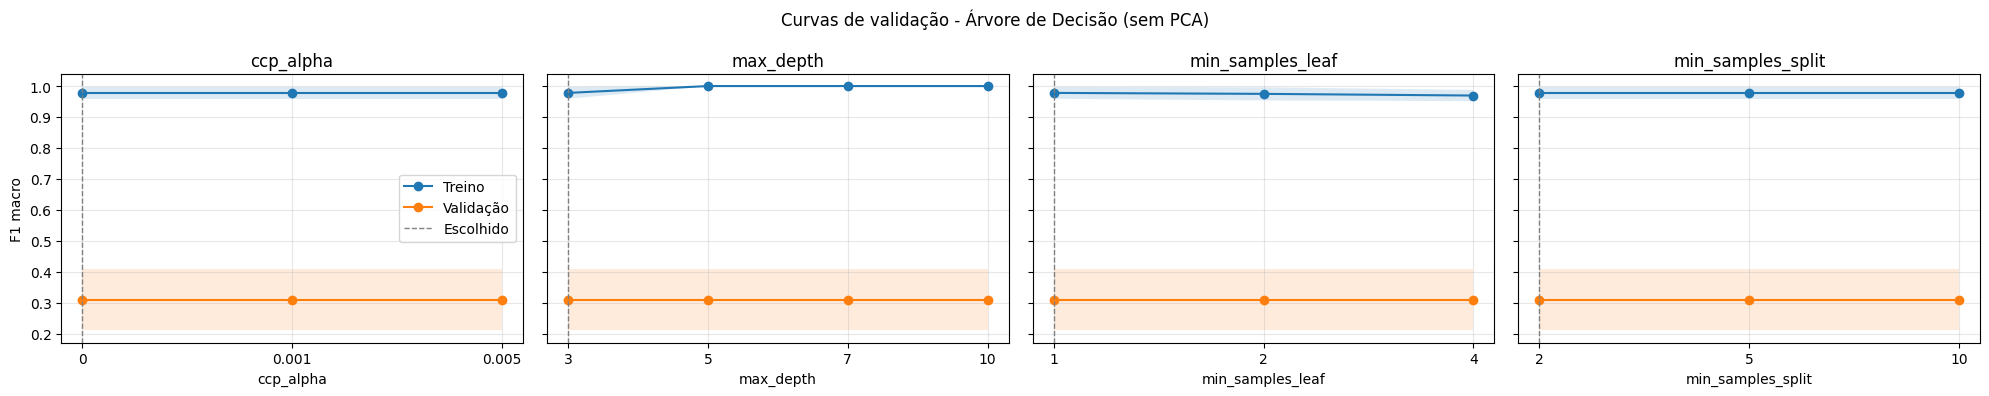

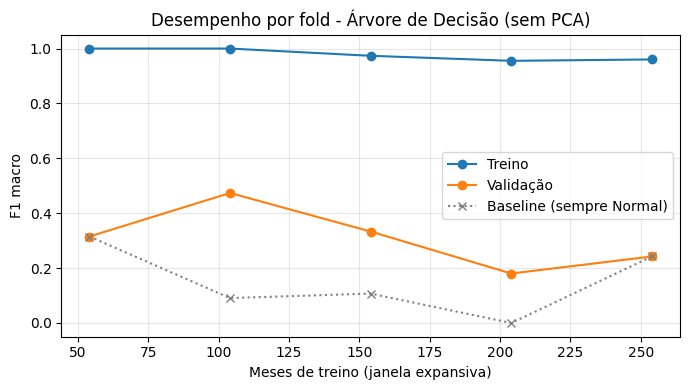

,fold,meses_treino,crises_treino,meses_val,crises_val,f1_treino,f1_validacao,f1_baseline
0,1,54,13,50,27,1.0000,0.3151,0.3151
1,2,104,40,50,45,1.0000,0.4737,0.0909
2,3,154,85,50,6,0.9736,0.3333,0.1071
3,4,204,91,50,50,0.9553,0.1803,0.0000
4,5,254,141,50,16,0.9603,0.2424,0.2424


Melhores parâmetros (PCA): {'ccp_alpha': 0.0, 'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 2}
F1 macro médio na validação: 0.3562

Top 10 configurações (PCA):


,rank_test_score,ccp_alpha,max_depth,min_samples_leaf,min_samples_split,mean_train_score,mean_test_score,std_test_score,gap_treino_val
3,1,0.000,3,2,2,0.8579,0.3562,0.1185,0.5016
4,1,0.000,3,2,5,0.8579,0.3562,0.1185,0.5016
5,1,0.000,3,2,10,0.8508,0.3562,0.1185,0.4946
39,1,0.001,3,2,2,0.8579,0.3562,0.1185,0.5016
40,1,0.001,3,2,5,0.8579,0.3562,0.1185,0.5016
41,1,0.001,3,2,10,0.8508,0.3562,0.1185,0.4946
2,7,0.000,3,1,10,0.8526,0.3544,0.1106,0.4982
0,7,0.000,3,1,2,0.8652,0.3544,0.1106,0.5108
38,7,0.001,3,1,10,0.8526,0.3544,0.1106,0.4982
1,7,0.000,3,1,5,0.8652,0.3544,0.1106,0.5108


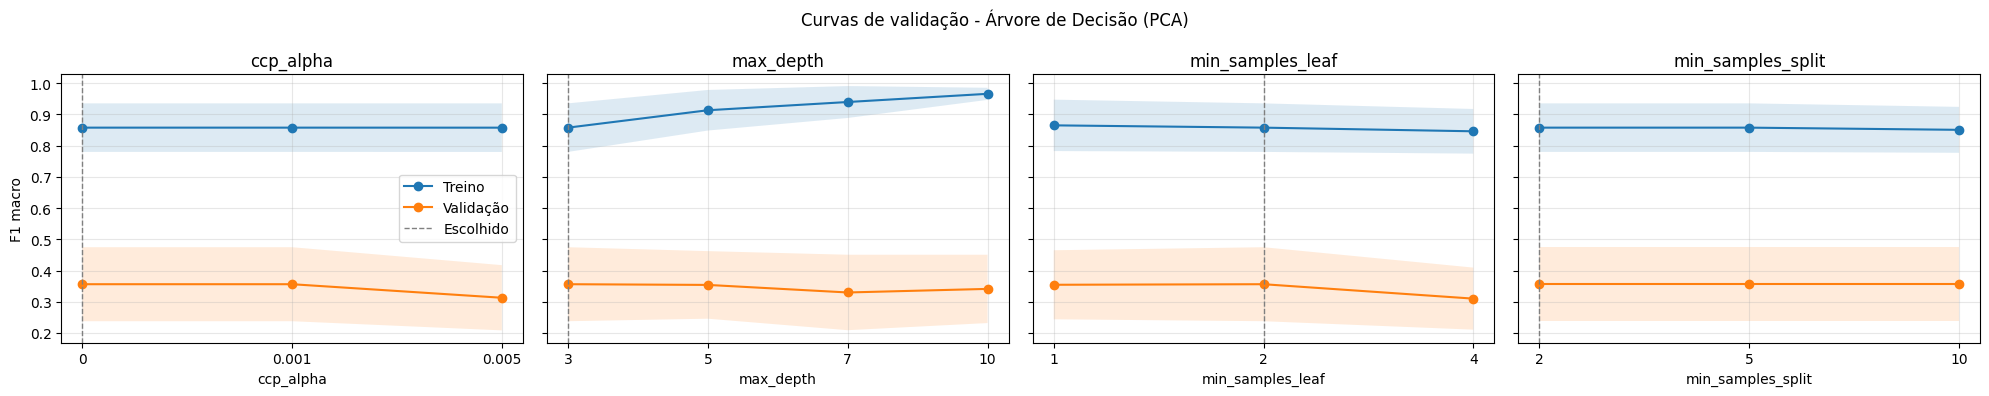

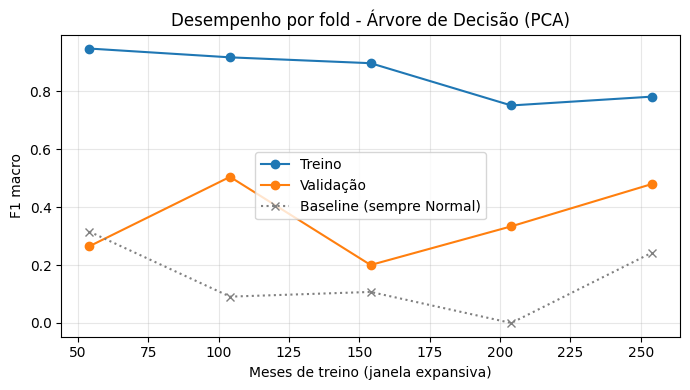

,fold,meses_treino,crises_treino,meses_val,crises_val,f1_treino,f1_validacao,f1_baseline
0,1,54,13,50,27,0.9464,0.2647,0.3151
1,2,104,40,50,45,0.9161,0.5040,0.0909
2,3,154,85,50,6,0.8959,0.2000,0.1071
3,4,204,91,50,50,0.7502,0.3333,0.0000
4,5,254,141,50,16,0.7806,0.4792,0.2424


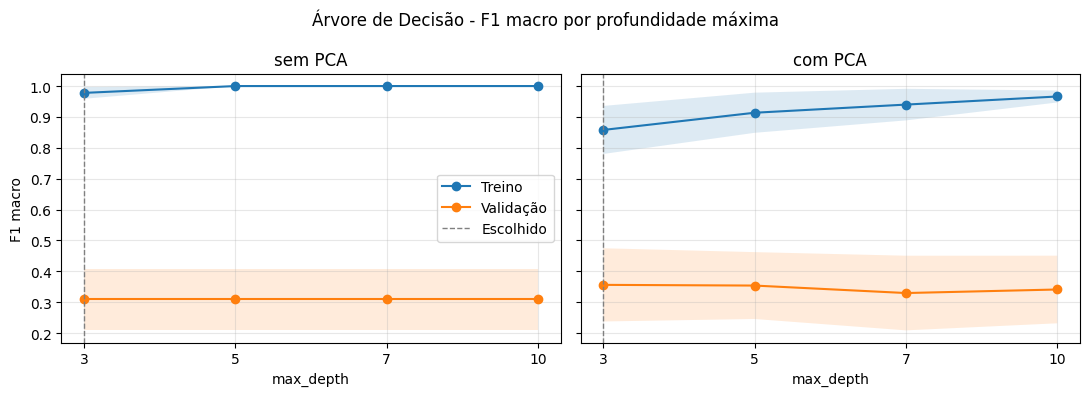

In [49]:
from sklearn.dummy import DummyClassifier

# ===== GRID DA ÁRVORE (mesmo grid da célula anterior) =====
param_grid_tree = {
    "max_depth": [3, 5, 7, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "ccp_alpha": [0.0, 0.001, 0.005]
}

def grid_com_treino(estimator, param_grid, X, y):
    # Refaz o grid search guardando também o score de treino de cada fold
    grid = GridSearchCV(
        estimator,
        param_grid,
        cv=tscv,
        scoring="f1_macro",
        n_jobs=-1,
        return_train_score=True
    )
    grid.fit(X, y)
    return grid

def top_configuracoes(grid, n=10):
    cv = pd.DataFrame(grid.cv_results_)
    colunas_param = [c for c in cv.columns if c.startswith("param_")]
    tabela = cv[["rank_test_score"] + colunas_param + ["mean_train_score", "mean_test_score", "std_test_score"]]
    tabela = tabela.sort_values("rank_test_score").head(n).copy()
    tabela["gap_treino_val"] = tabela["mean_train_score"] - tabela["mean_test_score"]
    tabela.columns = [c.replace("param_", "") for c in tabela.columns]
    return tabela.round(4)

def eh_none(v):
    # O sklearn pode guardar None como NaN quando a coluna é numérica (ex.: max_depth=[5, 10, None])
    return v is None or (isinstance(v, (float, np.floating)) and np.isnan(v))

def rotulo_param(v):
    # Rótulo padronizado: None/NaN -> "None", 5.0 -> "5", demais valores como texto
    if eh_none(v):
        return "None"
    if isinstance(v, (float, np.floating)) and float(v).is_integer():
        return str(int(v))
    return str(v)

def fatia_param(grid, param):
    # Linhas do cv_results_ variando só `param`, com os demais fixos nos melhores valores
    cv = pd.DataFrame(grid.cv_results_)
    melhores = grid.best_params_
    mascara = np.ones(len(cv), dtype=bool)
    for outro, valor in melhores.items():
        if outro != param:
            mascara &= (cv[f"param_{outro}"].map(rotulo_param) == rotulo_param(valor)).values
    # None vai para o final do eixo
    return cv[mascara].sort_values(
        f"param_{param}",
        key=lambda s: s.map(lambda v: (eh_none(v), 0 if eh_none(v) else v))
    )

def plot_curvas_validacao(grid, titulo):
    # Uma curva de validação por hiperparâmetro do grid
    melhores = grid.best_params_
    params = list(melhores.keys())

    fig, axes = plt.subplots(1, len(params), figsize=(5 * len(params), 4), sharey=True)

    for ax, param in zip(axes, params):
        fatia = fatia_param(grid, param)
        x = np.arange(len(fatia))
        rotulos = fatia[f"param_{param}"].map(rotulo_param).tolist()

        for prefixo, nome in [("train", "Treino"), ("test", "Validação")]:
            media = fatia[f"mean_{prefixo}_score"].values
            desvio = fatia[f"std_{prefixo}_score"].values
            ax.plot(x, media, marker="o", label=nome)
            ax.fill_between(x, media - desvio, media + desvio, alpha=0.15)

        ax.axvline(rotulos.index(rotulo_param(melhores[param])), color="gray", linestyle="--", linewidth=1, label="Escolhido")
        ax.set_xticks(x)
        ax.set_xticklabels(rotulos)
        ax.set_xlabel(param)
        ax.set_title(param)
        ax.grid(alpha=0.3)

    axes[0].set_ylabel("F1 macro")
    axes[0].legend()
    fig.suptitle(f"Curvas de validação - {titulo}")
    plt.tight_layout()
    plt.show()

def plot_comparativo_param(grid_sem, grid_com, param, titulo):
    # Figura para o documento: um hiperparâmetro, sem PCA x com PCA
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

    for ax, grid, versao in [(axes[0], grid_sem, "sem PCA"), (axes[1], grid_com, "com PCA")]:
        fatia = fatia_param(grid, param)
        x = np.arange(len(fatia))
        rotulos = fatia[f"param_{param}"].map(rotulo_param).tolist()

        for prefixo, nome in [("train", "Treino"), ("test", "Validação")]:
            media = fatia[f"mean_{prefixo}_score"].values
            desvio = fatia[f"std_{prefixo}_score"].values
            ax.plot(x, media, marker="o", label=nome)
            ax.fill_between(x, media - desvio, media + desvio, alpha=0.15)

        ax.axvline(rotulos.index(rotulo_param(grid.best_params_[param])), color="gray", linestyle="--", linewidth=1, label="Escolhido")
        ax.set_xticks(x)
        ax.set_xticklabels(rotulos)
        ax.set_xlabel(param)
        ax.set_title(versao)
        ax.grid(alpha=0.3)

    axes[0].set_ylabel("F1 macro")
    axes[0].legend()
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

def desempenho_por_fold(grid, X, y, titulo):
    # O TimeSeriesSplit é uma janela expansiva: cada fold treina com mais meses que o anterior.
    # Mostra o F1 do melhor modelo em cada fold, a quantidade de crises e um baseline que sempre prevê "Normal".
    idx = grid.best_index_
    cv = grid.cv_results_
    linhas = []

    for i, (idx_treino, idx_val) in enumerate(tscv.split(X)):
        y_tr, y_val = y.iloc[idx_treino], y.iloc[idx_val]

        baseline = DummyClassifier(strategy="most_frequent").fit(X.iloc[idx_treino], y_tr)
        f1_baseline = f1_score(y_val, baseline.predict(X.iloc[idx_val]), average="macro", labels=ALL_CLASSES, zero_division=0)

        linhas.append({
            "fold": i + 1,
            "meses_treino": len(idx_treino),
            "crises_treino": int(y_tr.sum()),
            "meses_val": len(idx_val),
            "crises_val": int(y_val.sum()),
            "f1_treino": cv[f"split{i}_train_score"][idx],
            "f1_validacao": cv[f"split{i}_test_score"][idx],
            "f1_baseline": f1_baseline
        })

    tabela = pd.DataFrame(linhas).round(4)

    plt.figure(figsize=(7, 4))
    plt.plot(tabela["meses_treino"], tabela["f1_treino"], marker="o", label="Treino")
    plt.plot(tabela["meses_treino"], tabela["f1_validacao"], marker="o", label="Validação")
    plt.plot(tabela["meses_treino"], tabela["f1_baseline"], marker="x", linestyle=":", color="gray", label="Baseline (sempre Normal)")
    plt.xlabel("Meses de treino (janela expansiva)")
    plt.ylabel("F1 macro")
    plt.title(f"Desempenho por fold - {titulo}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return tabela

# =====================================================
# ÁRVORE SEM PCA
# =====================================================

grid_tree_no_pca = grid_com_treino(DecisionTreeClassifier(random_state=42), param_grid_tree, X_train_no_pca, y_train_no_pca)

print("Melhores parâmetros (sem PCA):", grid_tree_no_pca.best_params_)
print(f"F1 macro médio na validação: {grid_tree_no_pca.best_score_:.4f}")
print("\nTop 10 configurações (sem PCA):")
display(top_configuracoes(grid_tree_no_pca))

plot_curvas_validacao(grid_tree_no_pca, "Árvore de Decisão (sem PCA)")
display(desempenho_por_fold(grid_tree_no_pca, X_train_no_pca, y_train_no_pca, "Árvore de Decisão (sem PCA)"))

# =====================================================
# ÁRVORE COM PCA
# =====================================================

grid_tree_pca = grid_com_treino(DecisionTreeClassifier(random_state=42), param_grid_tree, X_train_pca, y_train_pca)

print("Melhores parâmetros (PCA):", grid_tree_pca.best_params_)
print(f"F1 macro médio na validação: {grid_tree_pca.best_score_:.4f}")
print("\nTop 10 configurações (PCA):")
display(top_configuracoes(grid_tree_pca))

plot_curvas_validacao(grid_tree_pca, "Árvore de Decisão (PCA)")
display(desempenho_por_fold(grid_tree_pca, X_train_pca, y_train_pca, "Árvore de Decisão (PCA)"))

# =====================================================
# FIGURA PARA O DOCUMENTO
# =====================================================

plot_comparativo_param(grid_tree_no_pca, grid_tree_pca, "max_depth", "Árvore de Decisão - F1 macro por profundidade máxima")

KNN

Melhores parâmetros (sem PCA):
{'model__metric': 'manhattan', 'model__n_neighbors': 11, 'model__weights': 'uniform'}

===== KNN (sem PCA) =====

--- TREINO ---
              precision    recall  f1-score   support

      Normal       0.89      0.95      0.91       147
       Crise       0.95      0.89      0.91       157

    accuracy                           0.91       304
   macro avg       0.92      0.92      0.91       304
weighted avg       0.92      0.91      0.91       304


--- TESTE ---
              precision    recall  f1-score   support

      Normal       0.70      0.67      0.69        91
       Crise       0.32      0.35      0.33        40

    accuracy                           0.57       131
   macro avg       0.51      0.51      0.51       131
weighted avg       0.58      0.57      0.58       131


Tempo de treino: 1.3128 s
Tempo de predição: 39.8972 ms
Memória utilizada: 518.00 MB


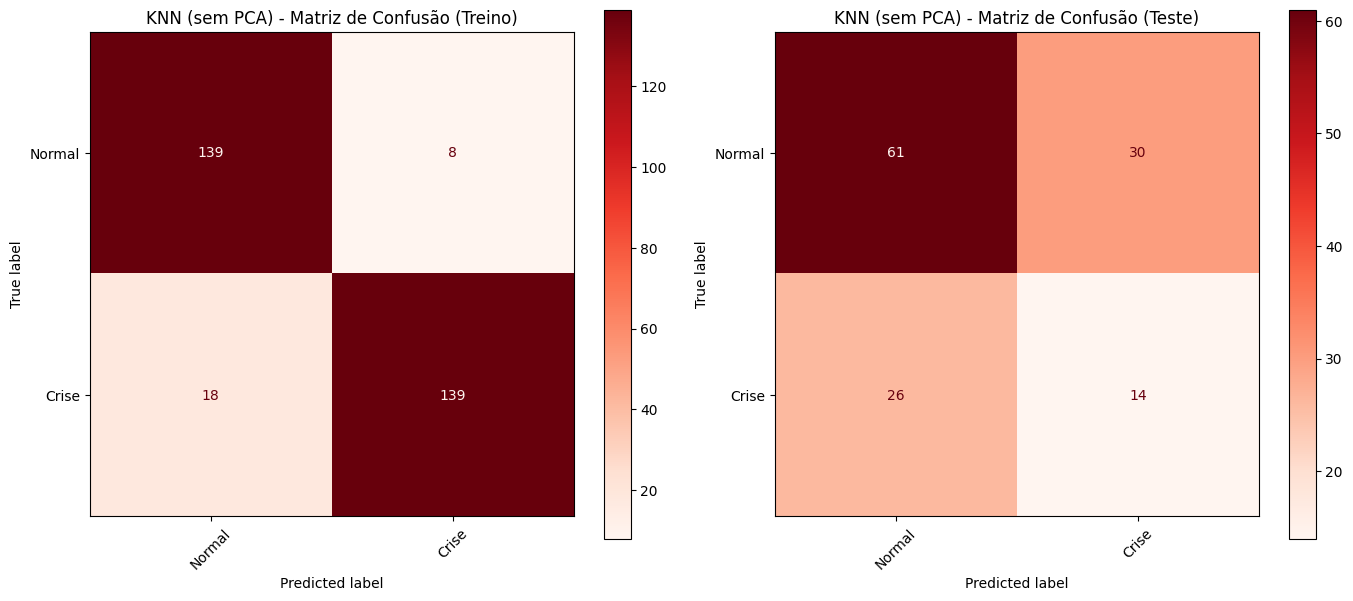

Melhores parâmetros (PCA):
{'model__metric': 'manhattan', 'model__n_neighbors': 3, 'model__weights': 'distance'}

===== KNN (PCA) =====

--- TREINO ---
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       147
       Crise       1.00      1.00      1.00       157

    accuracy                           1.00       304
   macro avg       1.00      1.00      1.00       304
weighted avg       1.00      1.00      1.00       304


--- TESTE ---
              precision    recall  f1-score   support

      Normal       0.89      0.46      0.61        91
       Crise       0.42      0.88      0.56        40

    accuracy                           0.59       131
   macro avg       0.66      0.67      0.59       131
weighted avg       0.75      0.59      0.60       131


Tempo de treino: 0.9387 s
Tempo de predição: 8.0023 ms
Memória utilizada: 491.70 MB


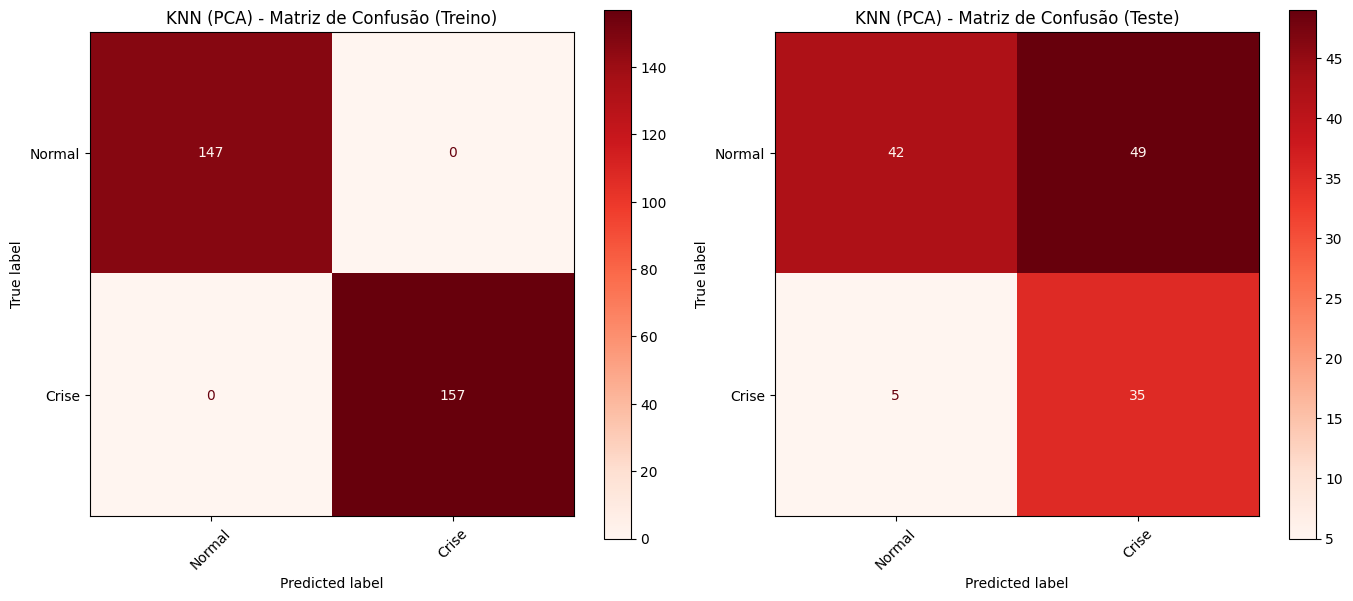

In [50]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# ===== PIPELINE =====
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier())
])

# ===== GRID =====
param_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"],
    "model__metric": ["euclidean", "manhattan"]
}

# =====================================================
# TREINAR SEM PCA
# =====================================================

grid_no_pca = GridSearchCV(
    knn_pipeline,
    param_grid,
    cv=tscv,
    scoring="f1_macro",
    n_jobs=-1
)

inicio_treino = time.time()

grid_no_pca.fit(X_train_no_pca, y_train_no_pca)

tempo_treino = time.time() - inicio_treino

best_knn_no_pca = grid_no_pca.best_estimator_

processo = psutil.Process(os.getpid())
memoria_mb = processo.memory_info().rss / 1024 / 1024

inicio_predicao = time.time()

best_knn_no_pca.predict(X_test_no_pca)

tempo_predicao = time.time() - inicio_predicao

print("Melhores parâmetros (sem PCA):")
print(grid_no_pca.best_params_)

avaliar_modelo(
    best_knn_no_pca,
    X_train_no_pca,
    X_test_no_pca,
    y_train_no_pca,
    y_test_no_pca,
    nome_modelo="KNN (sem PCA)",
    tempo_treino=tempo_treino,
    tempo_predicao=tempo_predicao,
    memoria_mb=memoria_mb
)

# =====================================================
# TREINAR COM PCA
# =====================================================

grid_pca = GridSearchCV(
    knn_pipeline,
    param_grid,
    cv=tscv,
    scoring="f1_macro",
    n_jobs=-1
)

inicio_treino = time.time()

grid_pca.fit(X_train_pca, y_train_pca)

tempo_treino = time.time() - inicio_treino

best_knn_pca = grid_pca.best_estimator_

processo = psutil.Process(os.getpid())
memoria_mb = processo.memory_info().rss / 1024 / 1024

inicio_predicao = time.time()

best_knn_pca.predict(X_test_pca)

tempo_predicao = time.time() - inicio_predicao

print("Melhores parâmetros (PCA):")
print(grid_pca.best_params_)

avaliar_modelo(
    best_knn_pca,
    X_train_pca,
    X_test_pca,
    y_train_pca,
    y_test_pca,
    nome_modelo="KNN (PCA)",
    tempo_treino=tempo_treino,
    tempo_predicao=tempo_predicao,
    memoria_mb=memoria_mb
)

KNN - Curvas de validação

Melhores parâmetros (sem PCA): {'model__metric': 'manhattan', 'model__n_neighbors': 11, 'model__weights': 'uniform'}
F1 macro médio na validação: 0.3503

Top 10 configurações (sem PCA):


,rank_test_score,model__metric,model__n_neighbors,model__weights,mean_train_score,mean_test_score,std_test_score,gap_treino_val
23,1,manhattan,11,distance,1.0000,0.3503,0.1608,0.6497
22,1,manhattan,11,uniform,0.9212,0.3503,0.1608,0.5710
24,3,manhattan,15,uniform,0.9390,0.3452,0.1532,0.5937
21,4,manhattan,9,distance,1.0000,0.3429,0.1239,0.6571
25,5,manhattan,15,distance,1.0000,0.3410,0.1486,0.6590
26,6,manhattan,21,uniform,0.9174,0.3409,0.1370,0.5765
27,6,manhattan,21,distance,1.0000,0.3409,0.1370,0.6591
20,8,manhattan,9,uniform,0.9604,0.3361,0.1313,0.6242
15,9,manhattan,3,distance,1.0000,0.3358,0.0554,0.6642
14,10,manhattan,3,uniform,0.9898,0.3337,0.0578,0.6561


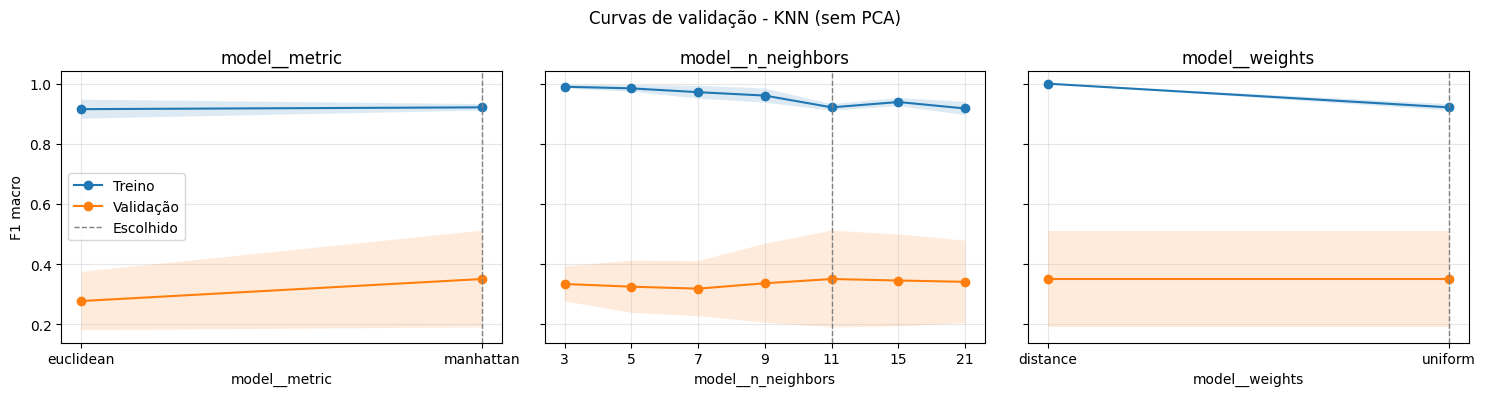

Melhores parâmetros (PCA): {'model__metric': 'manhattan', 'model__n_neighbors': 3, 'model__weights': 'distance'}
F1 macro médio na validação: 0.3035

Top 10 configurações (PCA):


,rank_test_score,model__metric,model__n_neighbors,model__weights,mean_train_score,mean_test_score,std_test_score,gap_treino_val
15,1,manhattan,3,distance,1.0000,0.3035,0.0946,0.6965
1,2,euclidean,3,distance,1.0000,0.3000,0.0805,0.7000
14,3,manhattan,3,uniform,0.9348,0.2950,0.1006,0.6398
0,4,euclidean,3,uniform,0.9353,0.2915,0.0865,0.6438
3,5,euclidean,5,distance,1.0000,0.2891,0.0960,0.7109
5,6,euclidean,7,distance,1.0000,0.2876,0.1228,0.7124
2,7,euclidean,5,uniform,0.9249,0.2849,0.0965,0.6400
4,8,euclidean,7,uniform,0.9226,0.2834,0.1231,0.6392
17,9,manhattan,5,distance,1.0000,0.2784,0.1160,0.7216
19,10,manhattan,7,distance,1.0000,0.2784,0.1114,0.7216


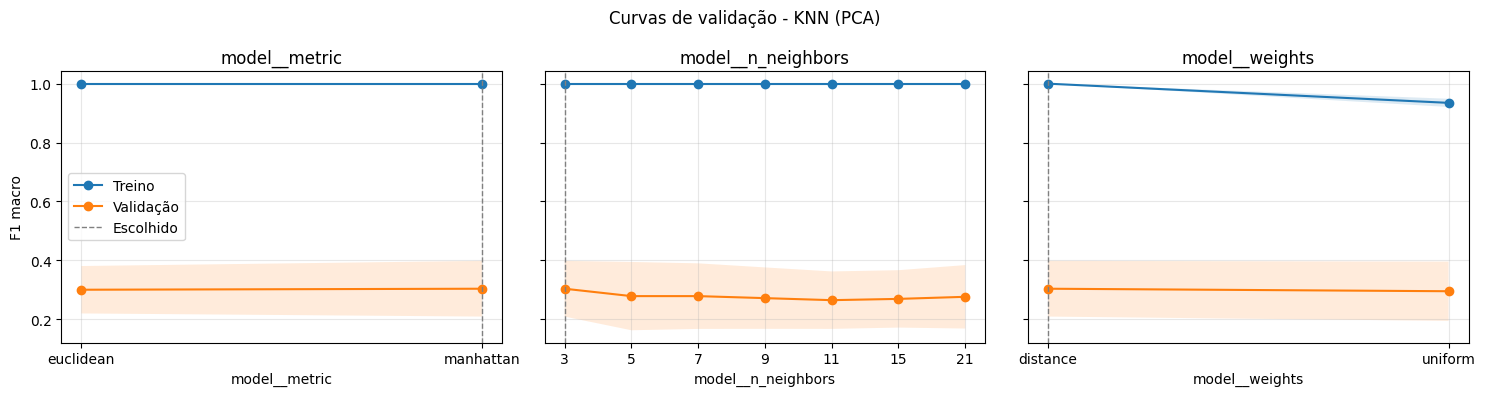

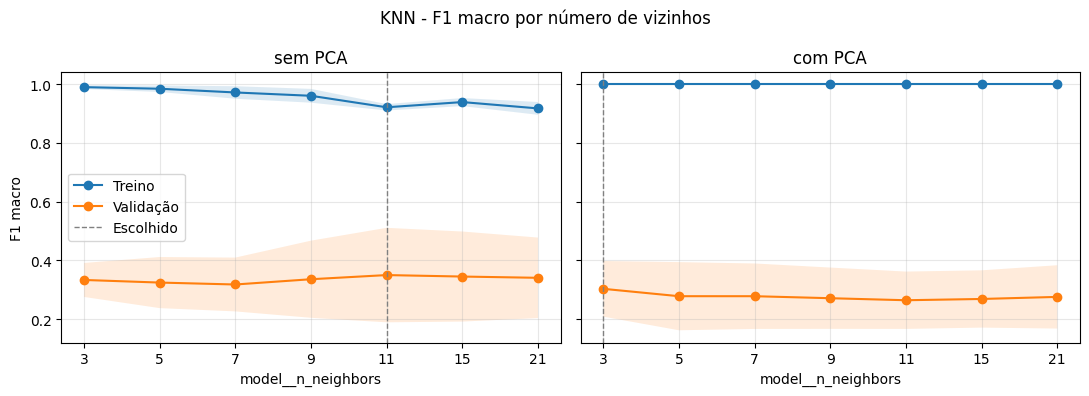

In [51]:
# ===== GRID DO KNN (mesmo grid da célula anterior) =====
# Usa as funções auxiliares definidas na célula de curvas da Árvore de Decisão
param_grid_knn = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"],
    "model__metric": ["euclidean", "manhattan"]
}

def knn_pipeline_base():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier())
    ])

# =====================================================
# KNN SEM PCA
# =====================================================

grid_knn_no_pca = grid_com_treino(knn_pipeline_base(), param_grid_knn, X_train_no_pca, y_train_no_pca)

print("Melhores parâmetros (sem PCA):", grid_knn_no_pca.best_params_)
print(f"F1 macro médio na validação: {grid_knn_no_pca.best_score_:.4f}")
print("\nTop 10 configurações (sem PCA):")
display(top_configuracoes(grid_knn_no_pca))

plot_curvas_validacao(grid_knn_no_pca, "KNN (sem PCA)")

# =====================================================
# KNN COM PCA
# =====================================================

grid_knn_pca = grid_com_treino(knn_pipeline_base(), param_grid_knn, X_train_pca, y_train_pca)

print("Melhores parâmetros (PCA):", grid_knn_pca.best_params_)
print(f"F1 macro médio na validação: {grid_knn_pca.best_score_:.4f}")
print("\nTop 10 configurações (PCA):")
display(top_configuracoes(grid_knn_pca))

plot_curvas_validacao(grid_knn_pca, "KNN (PCA)")

# =====================================================
# FIGURA PARA O DOCUMENTO
# =====================================================

plot_comparativo_param(grid_knn_no_pca, grid_knn_pca, "model__n_neighbors", "KNN - F1 macro por número de vizinhos")

Random Forest

Melhores parâmetros (sem PCA):
{'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

===== Random Forest (sem PCA) =====

--- TREINO ---
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       147
       Crise       1.00      1.00      1.00       157

    accuracy                           1.00       304
   macro avg       1.00      1.00      1.00       304
weighted avg       1.00      1.00      1.00       304


--- TESTE ---
              precision    recall  f1-score   support

      Normal       0.77      0.63      0.69        91
       Crise       0.40      0.57      0.47        40

    accuracy                           0.61       131
   macro avg       0.59      0.60      0.58       131
weighted avg       0.66      0.61      0.62       131


Tempo de treino: 74.3414 s
Tempo de predição: 6.9978 ms
Memória utilizada: 500.96 MB


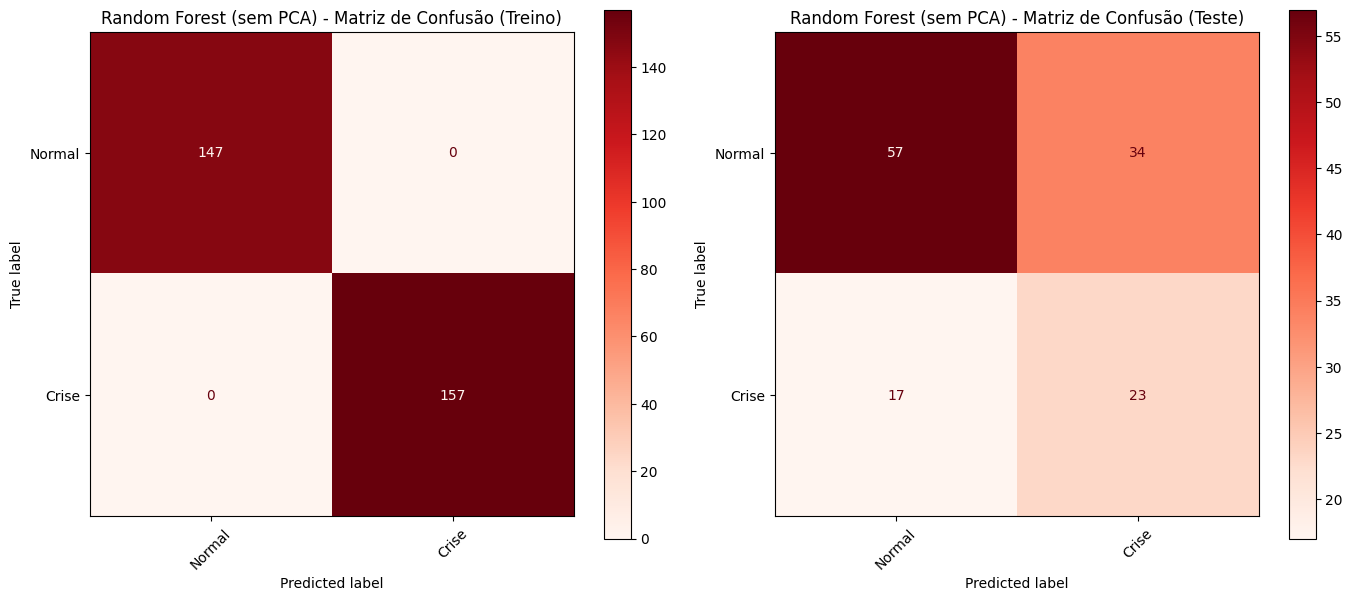


Importância das variáveis (sem PCA):
                      feature  importance
10           volatility_index    0.292482
5                 price_index    0.160246
12          yield_curve_slope    0.092572
2       industrial_production    0.091077
4   industrial_production_yoy    0.074390
8               real_interest    0.065891
0               credit_spread    0.059287
7               inflation_yoy    0.041394
1          credit_spread_diff    0.028338
13     yield_curve_slope_diff    0.023887
9          real_interest_diff    0.018828
6               inflation_mom    0.018435
11       volatility_index_mom    0.017818
3   industrial_production_mom    0.015353


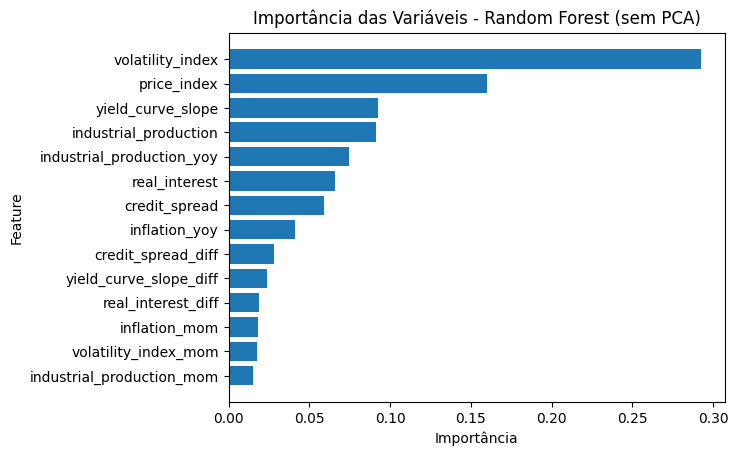

Melhores parâmetros (PCA):
{'class_weight': None, 'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 100}

===== Random Forest (PCA) =====

--- TREINO ---
              precision    recall  f1-score   support

      Normal       0.85      0.83      0.84       147
       Crise       0.84      0.87      0.86       157

    accuracy                           0.85       304
   macro avg       0.85      0.85      0.85       304
weighted avg       0.85      0.85      0.85       304


--- TESTE ---
              precision    recall  f1-score   support

      Normal       0.83      0.53      0.64        91
       Crise       0.41      0.75      0.53        40

    accuracy                           0.60       131
   macro avg       0.62      0.64      0.59       131
weighted avg       0.70      0.60      0.61       131


Tempo de treino: 64.6143 s
Tempo de predição: 11.8272 ms
Memória utilizada: 505.35 MB


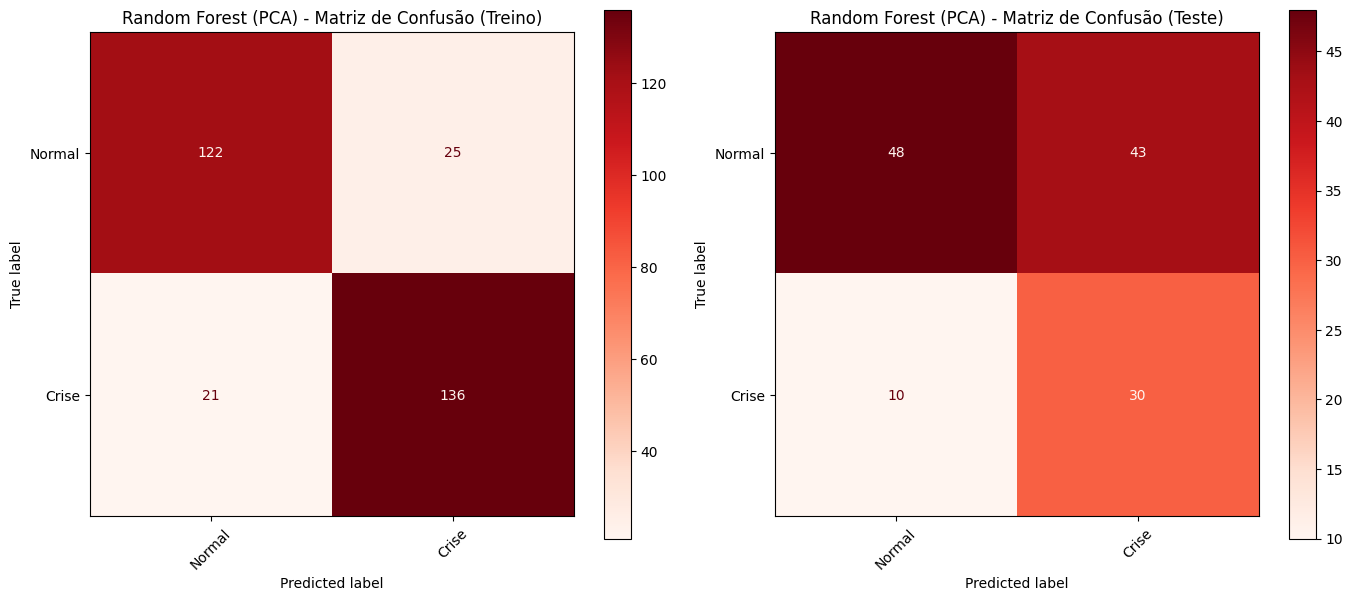


Importância das componentes PCA:
  feature  importance
2   pca_3    0.338696
1   pca_2    0.336041
0   pca_1    0.325263


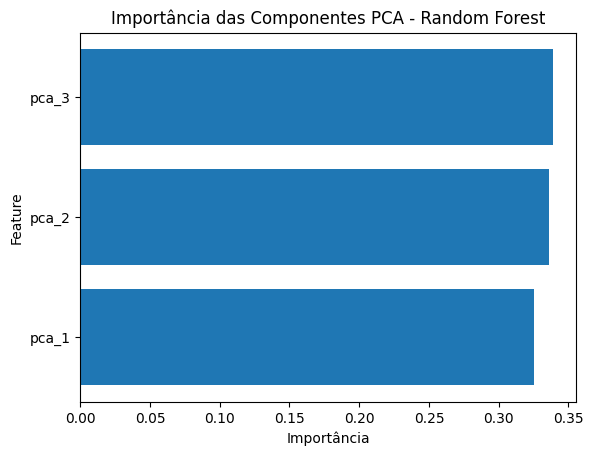

In [52]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
import pandas as pd
import matplotlib.pyplot as plt
import time
import psutil
import os

# ===== GRID DE HIPERPARÂMETROS =====
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "class_weight": [None, "balanced"]
}

# ===== MODELO BASE =====
rf = RandomForestClassifier(random_state=42)

# =====================================================
# TREINAR SEM PCA
# =====================================================

grid_no_pca = GridSearchCV(
    rf,
    param_grid,
    cv=tscv,
    scoring="f1_macro",
    n_jobs=-1
)

inicio_treino = time.time()

grid_no_pca.fit(X_train_no_pca, y_train_no_pca)

tempo_treino = time.time() - inicio_treino

best_rf_no_pca = grid_no_pca.best_estimator_

processo = psutil.Process(os.getpid())
memoria_mb = processo.memory_info().rss / 1024 / 1024

inicio_predicao = time.time()

best_rf_no_pca.predict(X_test_no_pca)

tempo_predicao = time.time() - inicio_predicao

print("Melhores parâmetros (sem PCA):")
print(grid_no_pca.best_params_)

avaliar_modelo(
    best_rf_no_pca,
    X_train_no_pca,
    X_test_no_pca,
    y_train_no_pca,
    y_test_no_pca,
    nome_modelo="Random Forest (sem PCA)",
    tempo_treino=tempo_treino,
    tempo_predicao=tempo_predicao,
    memoria_mb=memoria_mb
)

importances = best_rf_no_pca.feature_importances_

df_importance = pd.DataFrame({
    "feature": features,
    "importance": importances
}).sort_values(by="importance", ascending=False)

print("\nImportância das variáveis (sem PCA):")
print(df_importance)

plt.figure()
plt.barh(df_importance["feature"], df_importance["importance"])
plt.gca().invert_yaxis()
plt.title("Importância das Variáveis - Random Forest (sem PCA)")
plt.xlabel("Importância")
plt.ylabel("Feature")
plt.show()

# =====================================================
# TREINAR COM PCA
# =====================================================

grid_pca = GridSearchCV(
    rf,
    param_grid,
    cv=tscv,
    scoring="f1_macro",
    n_jobs=-1
)

inicio_treino = time.time()

grid_pca.fit(X_train_pca, y_train_pca)

tempo_treino = time.time() - inicio_treino

best_rf_pca = grid_pca.best_estimator_

processo = psutil.Process(os.getpid())
memoria_mb = processo.memory_info().rss / 1024 / 1024

inicio_predicao = time.time()

best_rf_pca.predict(X_test_pca)

tempo_predicao = time.time() - inicio_predicao

print("Melhores parâmetros (PCA):")
print(grid_pca.best_params_)

avaliar_modelo(
    best_rf_pca,
    X_train_pca,
    X_test_pca,
    y_train_pca,
    y_test_pca,
    nome_modelo="Random Forest (PCA)",
    tempo_treino=tempo_treino,
    tempo_predicao=tempo_predicao,
    memoria_mb=memoria_mb
)

importances_pca = best_rf_pca.feature_importances_

df_importance_pca = pd.DataFrame({
    "feature": ["pca_1", "pca_2", "pca_3"],
    "importance": importances_pca
}).sort_values(by="importance", ascending=False)

print("\nImportância das componentes PCA:")
print(df_importance_pca)

plt.figure()
plt.barh(df_importance_pca["feature"], df_importance_pca["importance"])
plt.gca().invert_yaxis()
plt.title("Importância das Componentes PCA - Random Forest")
plt.xlabel("Importância")
plt.ylabel("Feature")
plt.show()

Random Forest - Curvas de validação

Melhores parâmetros (sem PCA): {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
F1 macro médio na validação: 0.2939

Top 10 configurações (sem PCA):


,rank_test_score,class_weight,max_depth,min_samples_leaf,min_samples_split,n_estimators,mean_train_score,mean_test_score,std_test_score,gap_treino_val
90,1,balanced,None,1,2,100,1.0000,0.2939,0.1142,0.7061
72,1,balanced,10,1,2,100,1.0000,0.2939,0.1142,0.7061
54,3,balanced,5,1,2,100,0.9984,0.2911,0.1250,0.7073
20,4,None,10,1,5,100,1.0000,0.2847,0.1040,0.7153
38,4,None,None,1,5,100,1.0000,0.2847,0.1040,0.7153
2,6,None,5,1,5,100,0.9982,0.2835,0.1064,0.7147
18,7,None,10,1,2,100,1.0000,0.2793,0.1092,0.7207
36,7,None,None,1,2,100,1.0000,0.2793,0.1092,0.7207
39,9,None,None,1,5,200,1.0000,0.2765,0.1122,0.7235
21,9,None,10,1,5,200,1.0000,0.2765,0.1122,0.7235


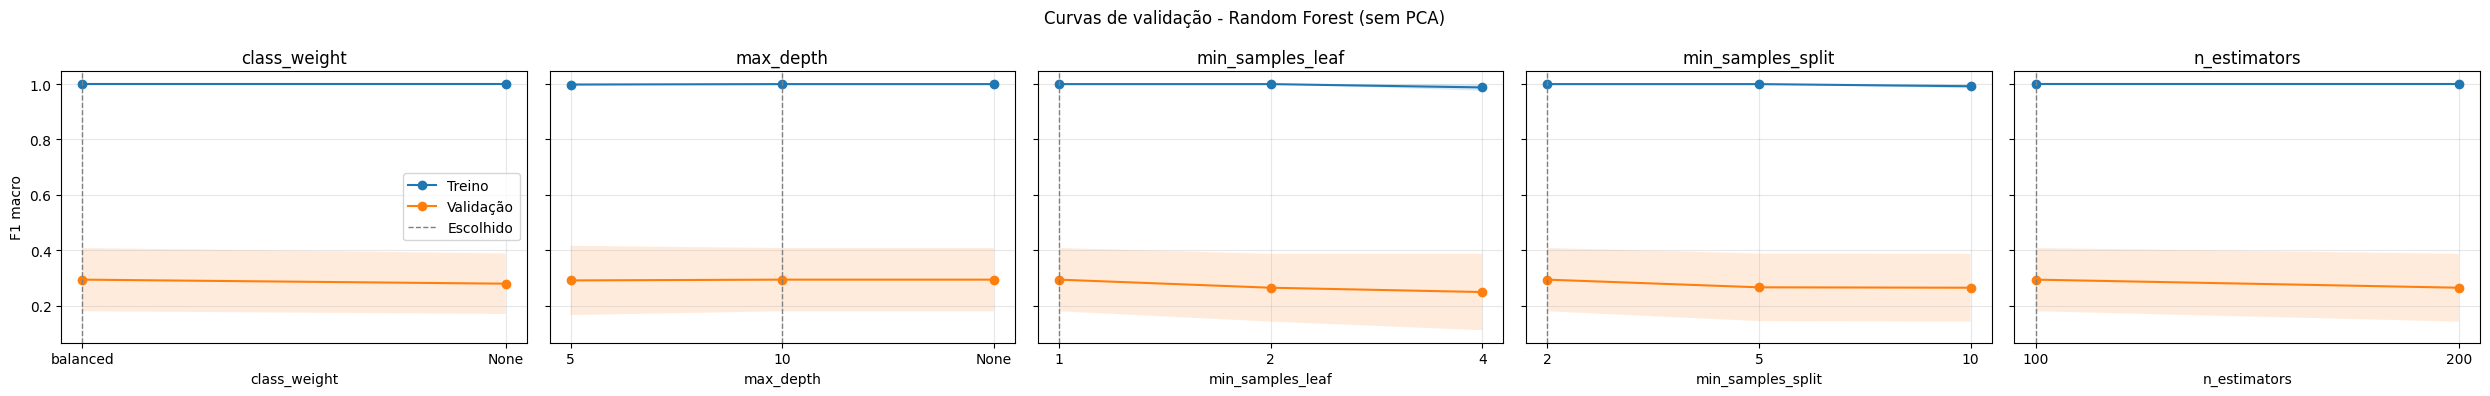

Melhores parâmetros (PCA): {'class_weight': None, 'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 100}
F1 macro médio na validação: 0.3035

Top 10 configurações (PCA):


,rank_test_score,class_weight,max_depth,min_samples_leaf,min_samples_split,n_estimators,mean_train_score,mean_test_score,std_test_score,gap_treino_val
10,1,None,5,2,10,100,0.9197,0.3035,0.1289,0.6162
18,2,None,10,1,2,100,1.0000,0.3008,0.1304,0.6992
1,3,None,5,1,2,200,0.9367,0.3001,0.1321,0.6366
55,3,balanced,5,1,2,200,0.9442,0.3001,0.1321,0.6441
4,5,None,5,1,10,100,0.9238,0.3000,0.1280,0.6238
60,6,balanced,5,2,2,100,0.9355,0.2998,0.1328,0.6356
11,7,None,5,2,10,200,0.9195,0.2984,0.1315,0.6210
54,7,balanced,5,1,2,100,0.9486,0.2984,0.1315,0.6501
57,7,balanced,5,1,5,200,0.9365,0.2984,0.1315,0.6380
64,10,balanced,5,2,10,100,0.9201,0.2974,0.1340,0.6227


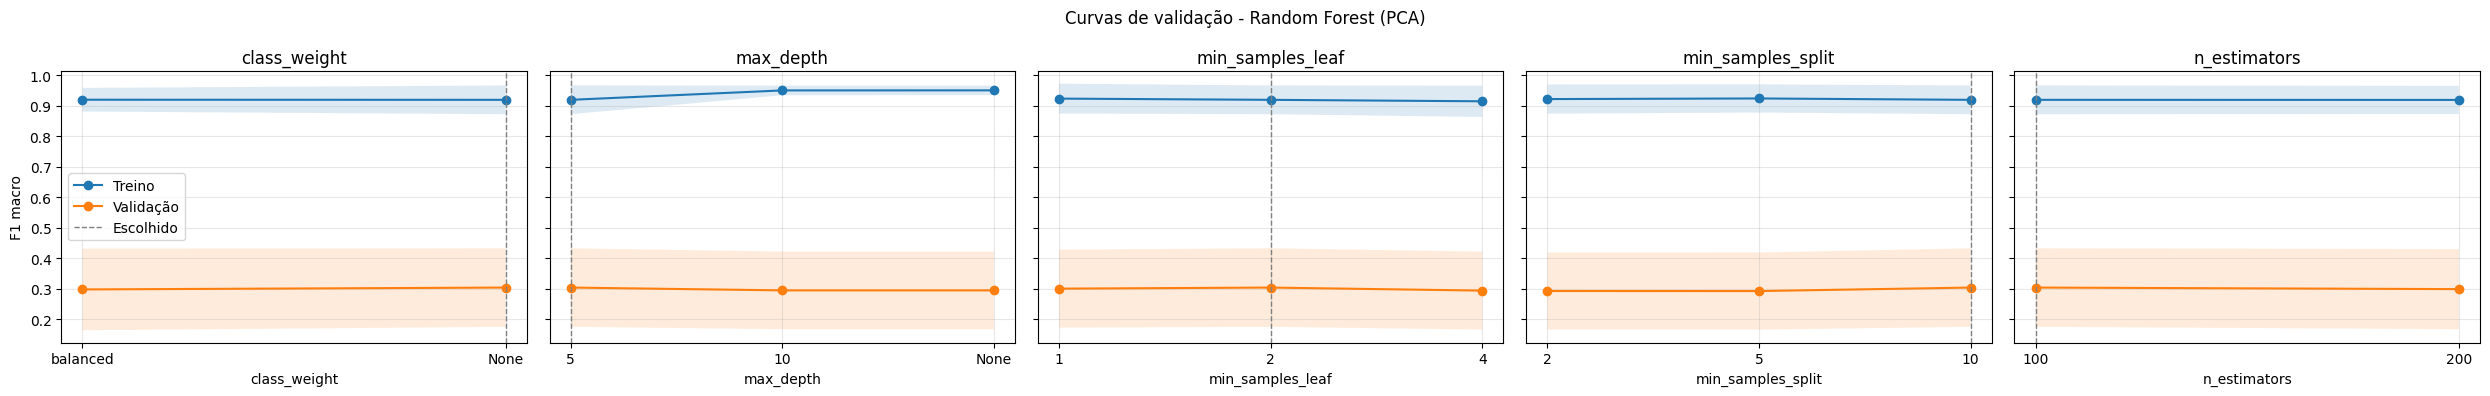

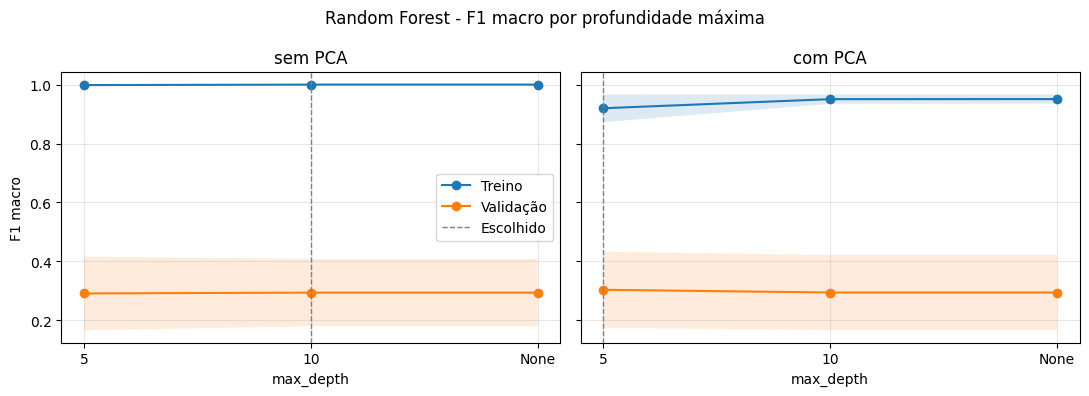

In [53]:
# ===== GRID DO RANDOM FOREST (mesmo grid da célula anterior) =====
# Usa as funções auxiliares definidas na célula de curvas da Árvore de Decisão
param_grid_rf = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "class_weight": [None, "balanced"]
}

# =====================================================
# RANDOM FOREST SEM PCA
# =====================================================

grid_rf_no_pca = grid_com_treino(RandomForestClassifier(random_state=42), param_grid_rf, X_train_no_pca, y_train_no_pca)

print("Melhores parâmetros (sem PCA):", grid_rf_no_pca.best_params_)
print(f"F1 macro médio na validação: {grid_rf_no_pca.best_score_:.4f}")
print("\nTop 10 configurações (sem PCA):")
display(top_configuracoes(grid_rf_no_pca))

plot_curvas_validacao(grid_rf_no_pca, "Random Forest (sem PCA)")

# =====================================================
# RANDOM FOREST COM PCA
# =====================================================

grid_rf_pca = grid_com_treino(RandomForestClassifier(random_state=42), param_grid_rf, X_train_pca, y_train_pca)

print("Melhores parâmetros (PCA):", grid_rf_pca.best_params_)
print(f"F1 macro médio na validação: {grid_rf_pca.best_score_:.4f}")
print("\nTop 10 configurações (PCA):")
display(top_configuracoes(grid_rf_pca))

plot_curvas_validacao(grid_rf_pca, "Random Forest (PCA)")

# =====================================================
# FIGURA PARA O DOCUMENTO
# =====================================================

plot_comparativo_param(grid_rf_no_pca, grid_rf_pca, "max_depth", "Random Forest - F1 macro por profundidade máxima")

Voting Ensemble

Melhores parâmetros (sem PCA):
{'logreg__model__C': 0.1, 'voting': 'hard'}

===== Voting Ensemble (sem PCA) =====

--- TREINO ---
              precision    recall  f1-score   support

      Normal       0.91      0.98      0.94       147
       Crise       0.98      0.90      0.94       157

    accuracy                           0.94       304
   macro avg       0.94      0.94      0.94       304
weighted avg       0.94      0.94      0.94       304


--- TESTE ---
              precision    recall  f1-score   support

      Normal       0.77      0.62      0.68        91
       Crise       0.40      0.57      0.47        40

    accuracy                           0.60       131
   macro avg       0.58      0.60      0.58       131
weighted avg       0.65      0.60      0.62       131


Tempo de treino: 3.8913 s
Tempo de predição: 25.4922 ms
Memória utilizada: 515.68 MB


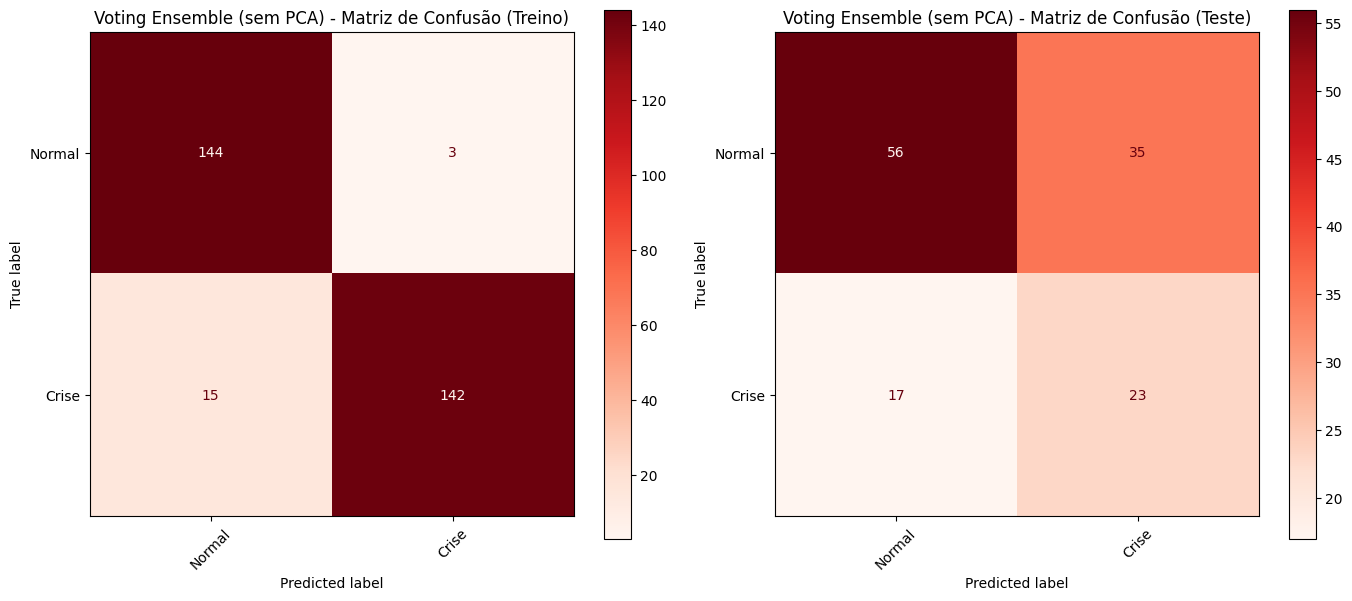

Melhores parâmetros (PCA):
{'logreg__model__C': 1, 'voting': 'soft'}

===== Voting Ensemble (PCA) =====

--- TREINO ---
              precision    recall  f1-score   support

      Normal       0.96      0.97      0.97       147
       Crise       0.97      0.96      0.97       157

    accuracy                           0.97       304
   macro avg       0.97      0.97      0.97       304
weighted avg       0.97      0.97      0.97       304


--- TESTE ---
              precision    recall  f1-score   support

      Normal       0.80      0.49      0.61        91
       Crise       0.39      0.72      0.50        40

    accuracy                           0.56       131
   macro avg       0.60      0.61      0.56       131
weighted avg       0.68      0.56      0.58       131


Tempo de treino: 3.5778 s
Tempo de predição: 18.7962 ms
Memória utilizada: 520.67 MB


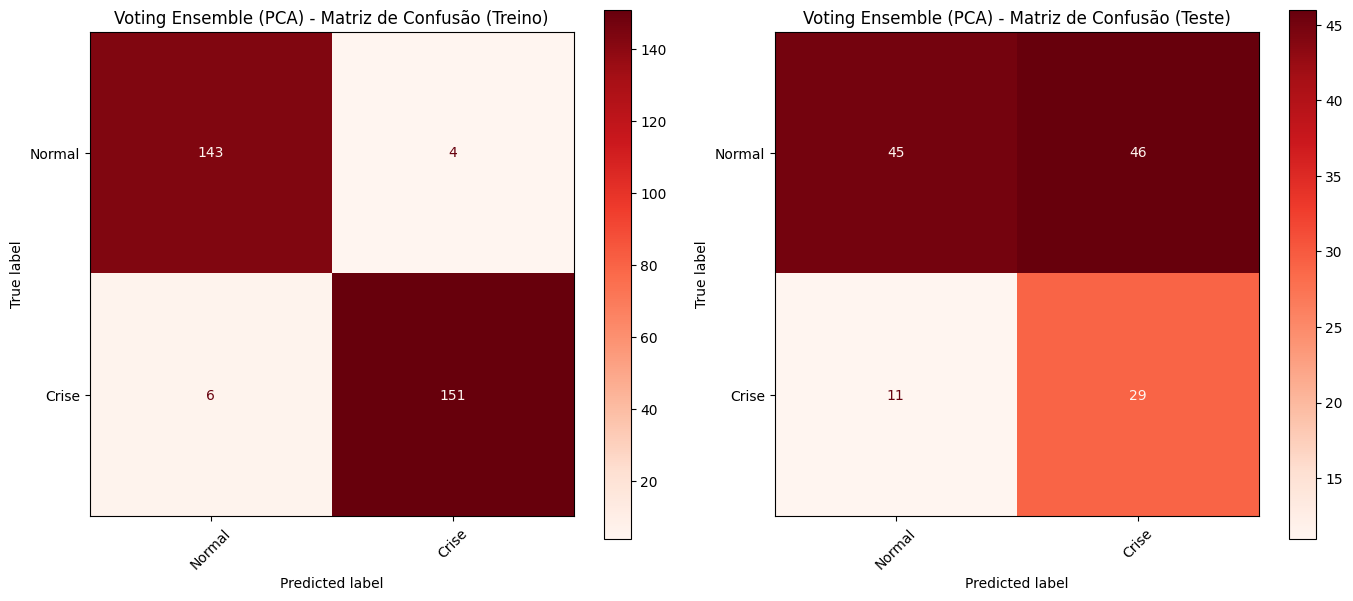

In [54]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

# ===== MODELOS BASE =====
# Usa os melhores KNN, Árvore e Random Forest encontrados nos grids de cada modelo
# (clone copia os hiperparâmetros sem copiar o treino) + Regressão Logística

def logreg_base():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, solver="lbfgs"))
    ])

def voting_base(knn, tree, rf):
    return VotingClassifier(estimators=[
        ("knn", clone(knn)),
        ("tree", clone(tree)),
        ("rf", clone(rf)),
        ("logreg", logreg_base())
    ])

# ===== GRID DE HIPERPARÂMETROS =====
param_grid_voting = {
    "voting": ["hard", "soft"],
    "logreg__model__C": [0.01, 0.1, 1, 10]
}

# =====================================================
# TREINAR SEM PCA
# =====================================================

grid_no_pca = GridSearchCV(
    voting_base(best_knn_no_pca, best_tree_no_pca, best_rf_no_pca),
    param_grid_voting,
    cv=tscv,
    scoring="f1_macro",
    n_jobs=-1
)

inicio_treino = time.time()

grid_no_pca.fit(X_train_no_pca, y_train_no_pca)

tempo_treino = time.time() - inicio_treino

best_voting_no_pca = grid_no_pca.best_estimator_

processo = psutil.Process(os.getpid())
memoria_mb = processo.memory_info().rss / 1024 / 1024

inicio_predicao = time.time()

best_voting_no_pca.predict(X_test_no_pca)

tempo_predicao = time.time() - inicio_predicao

print("Melhores parâmetros (sem PCA):")
print(grid_no_pca.best_params_)

avaliar_modelo(
    best_voting_no_pca,
    X_train_no_pca,
    X_test_no_pca,
    y_train_no_pca,
    y_test_no_pca,
    nome_modelo="Voting Ensemble (sem PCA)",
    tempo_treino=tempo_treino,
    tempo_predicao=tempo_predicao,
    memoria_mb=memoria_mb
)

# =====================================================
# TREINAR COM PCA
# =====================================================

grid_pca = GridSearchCV(
    voting_base(best_knn_pca, best_tree_pca, best_rf_pca),
    param_grid_voting,
    cv=tscv,
    scoring="f1_macro",
    n_jobs=-1
)

inicio_treino = time.time()

grid_pca.fit(X_train_pca, y_train_pca)

tempo_treino = time.time() - inicio_treino

best_voting_pca = grid_pca.best_estimator_

processo = psutil.Process(os.getpid())
memoria_mb = processo.memory_info().rss / 1024 / 1024

inicio_predicao = time.time()

best_voting_pca.predict(X_test_pca)

tempo_predicao = time.time() - inicio_predicao

print("Melhores parâmetros (PCA):")
print(grid_pca.best_params_)

avaliar_modelo(
    best_voting_pca,
    X_train_pca,
    X_test_pca,
    y_train_pca,
    y_test_pca,
    nome_modelo="Voting Ensemble (PCA)",
    tempo_treino=tempo_treino,
    tempo_predicao=tempo_predicao,
    memoria_mb=memoria_mb
)

Voting Ensemble - Curvas de validação

Melhores parâmetros (sem PCA): {'logreg__model__C': 0.1, 'voting': 'hard'}
F1 macro médio na validação: 0.3568

Top configurações (sem PCA):


,rank_test_score,logreg__model__C,voting,mean_train_score,mean_test_score,std_test_score,gap_treino_val
2,1,0.10,hard,0.9704,0.3568,0.1738,0.6136
4,2,1.00,hard,0.9801,0.3204,0.1243,0.6598
6,3,10.00,hard,0.9823,0.3084,0.1180,0.6739
5,4,1.00,soft,0.9871,0.3007,0.0954,0.6864
3,5,0.10,soft,0.9881,0.2969,0.0966,0.6912
7,5,10.00,soft,0.9871,0.2969,0.0966,0.6902
0,7,0.01,hard,0.9422,0.2932,0.1730,0.6490
1,8,0.01,soft,0.9881,0.2858,0.1101,0.7023


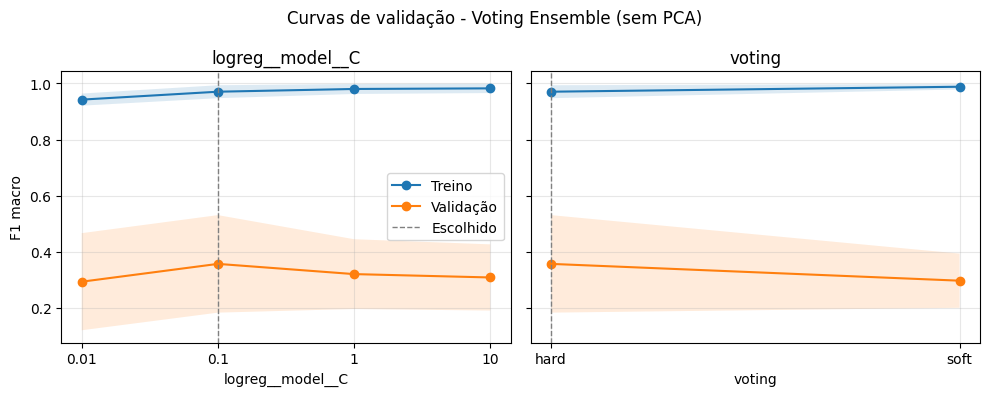

Melhores parâmetros (PCA): {'logreg__model__C': 1, 'voting': 'soft'}
F1 macro médio na validação: 0.2909

Top configurações (PCA):


,rank_test_score,logreg__model__C,voting,mean_train_score,mean_test_score,std_test_score,gap_treino_val
7,1,10.00,soft,0.9612,0.2909,0.1282,0.6703
5,1,1.00,soft,0.9645,0.2909,0.1282,0.6736
3,3,0.10,soft,0.9742,0.2888,0.1283,0.6854
2,4,0.10,hard,0.9194,0.2850,0.1201,0.6344
4,4,1.00,hard,0.9230,0.2850,0.1201,0.6380
6,4,10.00,hard,0.9230,0.2850,0.1201,0.6380
1,7,0.01,soft,0.9782,0.2835,0.1162,0.6947
0,8,0.01,hard,0.9126,0.2788,0.1202,0.6338


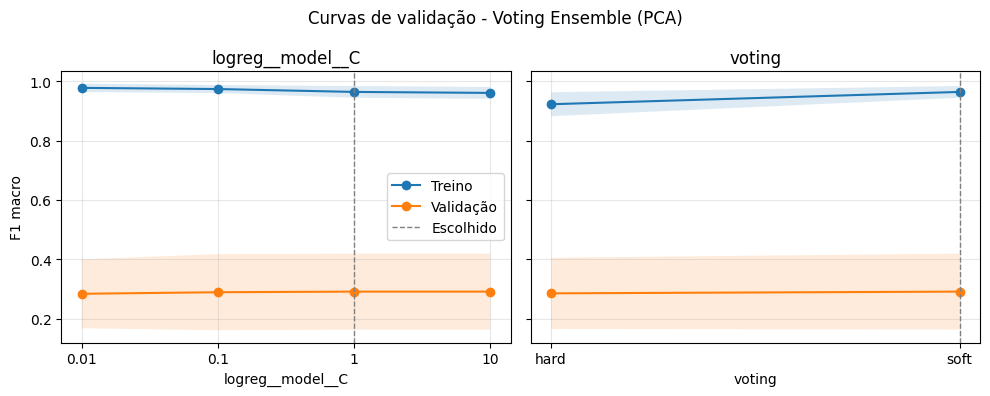

In [55]:
# Usa as funções auxiliares definidas na célula de curvas da Árvore de Decisão

# =====================================================
# VOTING SEM PCA
# =====================================================

grid_voting_no_pca = grid_com_treino(
    voting_base(best_knn_no_pca, best_tree_no_pca, best_rf_no_pca),
    param_grid_voting,
    X_train_no_pca,
    y_train_no_pca
)

print("Melhores parâmetros (sem PCA):", grid_voting_no_pca.best_params_)
print(f"F1 macro médio na validação: {grid_voting_no_pca.best_score_:.4f}")
print("\nTop configurações (sem PCA):")
display(top_configuracoes(grid_voting_no_pca))

plot_curvas_validacao(grid_voting_no_pca, "Voting Ensemble (sem PCA)")

# =====================================================
# VOTING COM PCA
# =====================================================

grid_voting_pca = grid_com_treino(
    voting_base(best_knn_pca, best_tree_pca, best_rf_pca),
    param_grid_voting,
    X_train_pca,
    y_train_pca
)

print("Melhores parâmetros (PCA):", grid_voting_pca.best_params_)
print(f"F1 macro médio na validação: {grid_voting_pca.best_score_:.4f}")
print("\nTop configurações (PCA):")
display(top_configuracoes(grid_voting_pca))

plot_curvas_validacao(grid_voting_pca, "Voting Ensemble (PCA)")

MLP Keras

In [ ]:
import tensorflow as tf

process = psutil.Process(os.getpid())

# Semente fixa e operações determinísticas: o MLP gera o mesmo resultado a cada execução
tf.config.experimental.enable_op_determinism()

class KerasBinaryWrapper:
    def __init__(self, model, threshold=0.5):
        self.model = model
        self.threshold = threshold

    def predict(self, X):
        probs = self.model.predict(X, verbose=0)
        return (probs > self.threshold).astype(int).ravel()


# ==========================
# MLP (Keras) - sem PCA
# Arquitetura 128 -> 64 e 185 épocas, escolhidas na comparação de arquiteturas
# ==========================

tf.keras.utils.set_random_seed(42)

mlp_keras = Sequential([
    Dense(units=128, activation='relu', input_shape=[X_train_scaled.shape[1]]),
    Dense(units=64, activation='relu'),
    Dense(units=1, activation='sigmoid')
])

mlp_keras.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

mem_before = process.memory_info().rss / (1024 ** 2)
inicio = time.time()
mlp_keras.fit(X_train_scaled, y_train_no_pca, epochs=185, verbose=0)
tempo_treino_mlp = time.time() - inicio
memoria_mlp = process.memory_info().rss / (1024 ** 2) - mem_before

mlp_wrapper = KerasBinaryWrapper(mlp_keras)

inicio_pred = time.time()
_ = mlp_wrapper.predict(X_test_scaled)
tempo_predicao_mlp = time.time() - inicio_pred

avaliar_modelo(
    mlp_wrapper,
    X_train_scaled,
    X_test_scaled,
    y_train_no_pca,
    y_test_no_pca,
    nome_modelo="MLP Keras (sem PCA)",
    tempo_treino=tempo_treino_mlp,
    tempo_predicao=tempo_predicao_mlp,
    memoria_mb=memoria_mlp
)

# ==========================
# MLP (Keras) - com PCA
# Arquitetura 32 e 10 épocas, escolhidas na comparação de arquiteturas
# ==========================

tf.keras.utils.set_random_seed(42)

mlp_keras_pca = Sequential([
    Dense(units=32, activation='relu', input_shape=[X_train_pca.shape[1]]),
    Dense(units=1, activation='sigmoid')
])

mlp_keras_pca.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

mem_before = process.memory_info().rss / (1024 ** 2)
inicio = time.time()
mlp_keras_pca.fit(X_train_pca, y_train_pca, epochs=10, verbose=0)
tempo_treino_mlp_pca = time.time() - inicio
memoria_mlp_pca = process.memory_info().rss / (1024 ** 2) - mem_before

mlp_wrapper_pca = KerasBinaryWrapper(mlp_keras_pca)

inicio_pred = time.time()
_ = mlp_wrapper_pca.predict(X_test_pca)
tempo_predicao_mlp_pca = time.time() - inicio_pred

avaliar_modelo(
    mlp_wrapper_pca,
    X_train_pca,
    X_test_pca,
    y_train_pca,
    y_test_pca,
    nome_modelo="MLP Keras (PCA)",
    tempo_treino=tempo_treino_mlp_pca,
    tempo_predicao=tempo_predicao_mlp_pca,
    memoria_mb=memoria_mlp_pca
)

MLP Keras - Curvas de aprendizado por época

In [60]:
import tensorflow as tf
from tensorflow.keras.callbacks import Callback

# Usa a mesma validação cruzada temporal (tscv) dos outros modelos para escolher o número de épocas
EPOCAS_MAX = 500
JANELA_SUAVIZACAO = 10

class MetricasValidacao(Callback):
    # Calcula precision e recall da classe Crise e F1 macro na validação ao final de cada época
    def __init__(self, X_val, y_val):
        super().__init__()
        self.X_val = tf.convert_to_tensor(X_val, dtype=tf.float32)
        self.y_val = np.asarray(y_val)
        self.historico = {"precision": [], "recall": [], "f1_macro": []}

    def on_epoch_end(self, epoch, logs=None):
        probs = self.model(self.X_val, training=False).numpy().ravel()
        y_pred = (probs > 0.5).astype(int)
        self.historico["precision"].append(precision_score(self.y_val, y_pred, pos_label=1, zero_division=0))
        self.historico["recall"].append(recall_score(self.y_val, y_pred, pos_label=1, zero_division=0))
        self.historico["f1_macro"].append(f1_score(self.y_val, y_pred, average="macro", labels=ALL_CLASSES, zero_division=0))

def criar_mlp(n_features, camadas=(64, 32)):
    # Camadas ocultas ReLU + saída sigmoide. O padrão (64, 32) é a arquitetura inicial do projeto
    ocultas = [Dense(units=camadas[0], activation='relu', input_shape=[n_features])]
    ocultas += [Dense(units=u, activation='relu') for u in camadas[1:]]
    model = Sequential(ocultas + [Dense(units=1, activation='sigmoid')])
    model.compile(optimizer='adam', loss='binary_crossentropy')
    return model

def curvas_por_epoca(X, y, camadas=(64, 32), epocas=EPOCAS_MAX):
    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y)
    curvas = {k: [] for k in ["loss_treino", "loss_val", "precision", "recall", "f1_macro"]}

    for idx_treino, idx_val in tscv.split(X):
        tf.keras.utils.set_random_seed(42)
        model = criar_mlp(X.shape[1], camadas)
        metricas = MetricasValidacao(X[idx_val], y[idx_val])

        hist = model.fit(
            X[idx_treino], y[idx_treino],
            validation_data=(X[idx_val], y[idx_val]),
            epochs=epocas,
            verbose=0,
            callbacks=[metricas]
        )

        curvas["loss_treino"].append(hist.history["loss"])
        curvas["loss_val"].append(hist.history["val_loss"])
        for k in ["precision", "recall", "f1_macro"]:
            curvas[k].append(metricas.historico[k])

    # Cada chave vira uma matriz (folds x épocas)
    return {k: np.array(v) for k, v in curvas.items()}

def suavizar(serie, janela=JANELA_SUAVIZACAO):
    # Média móvel com janela completa (as primeiras janela-1 épocas ficam sem valor)
    return pd.Series(serie).rolling(janela, min_periods=janela).mean().values

def epoca_escolhida(curvas):
    # Época com maior F1 macro médio na validação (mesmo critério dos grids), após suavização
    return int(np.nanargmax(suavizar(curvas["f1_macro"].mean(axis=0)))) + 1

def resumo_por_epoca(curvas, epocas=(10, 25, 50, 100, 200, 300, 400, 500)):
    n_epocas = curvas["loss_treino"].shape[1]
    return pd.DataFrame([{
        "epoca": e,
        "loss_treino": curvas["loss_treino"][:, e - 1].mean(),
        "loss_val": curvas["loss_val"][:, e - 1].mean(),
        "precision_crise_val": curvas["precision"][:, e - 1].mean(),
        "recall_crise_val": curvas["recall"][:, e - 1].mean(),
        "f1_macro_val": curvas["f1_macro"][:, e - 1].mean()
    } for e in epocas if e <= n_epocas]).round(4)

def plot_curvas_epoca(curvas_sem, curvas_com):
    # Linha 1: loss de treino x validação | Linha 2: métricas de validação. Colunas: sem PCA x com PCA
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)

    for col, (curvas, versao) in enumerate([(curvas_sem, "sem PCA"), (curvas_com, "com PCA")]):
        epocas = np.arange(1, curvas["loss_treino"].shape[1] + 1)
        escolhida = epoca_escolhida(curvas)

        ax = axes[0, col]
        ax.plot(epocas, curvas["loss_treino"].mean(axis=0), label="Loss treino")
        ax.plot(epocas, curvas["loss_val"].mean(axis=0), label="Loss validação")
        ax.axvline(escolhida, color="gray", linestyle="--", linewidth=1, label=f"Época escolhida ({escolhida})")
        ax.set_title(f"Loss (binary crossentropy) - {versao}")
        ax.set_ylabel("Loss")
        ax.grid(alpha=0.3)
        ax.legend()

        ax = axes[1, col]
        for chave, nome in [("recall", "Recall Crise"), ("precision", "Precision Crise"), ("f1_macro", "F1 macro")]:
            ax.plot(epocas, suavizar(curvas[chave].mean(axis=0)), label=nome)
        ax.axvline(escolhida, color="gray", linestyle="--", linewidth=1)
        ax.set_title(f"Métricas na validação - {versao}")
        ax.set_xlabel("Época")
        ax.set_ylabel("Valor (média dos folds)")
        ax.set_ylim(0, 1)
        ax.grid(alpha=0.3)
        ax.legend()

    fig.suptitle("MLP - Curvas de aprendizado por época (média dos 5 folds temporais)")
    plt.tight_layout()
    plt.show()

In [ ]:
# =====================================================
# CURVAS POR ÉPOCA - ARQUITETURA INICIAL (64 -> 32), 500 ÉPOCAS
# =====================================================

curvas_mlp_no_pca = curvas_por_epoca(X_train_scaled, y_train_no_pca)
curvas_mlp_pca = curvas_por_epoca(X_train_pca, y_train_pca)

for nome, curvas in [("sem PCA", curvas_mlp_no_pca), ("PCA", curvas_mlp_pca)]:
    loss_val_media = curvas["loss_val"].mean(axis=0)
    print(f"\n===== MLP ({nome}) =====")
    print(f"Época com maior F1 macro na validação (suavizado): {epoca_escolhida(curvas)}")
    print(f"Época com menor loss de validação: {int(np.argmin(loss_val_media)) + 1}")
    display(resumo_por_epoca(curvas))

plot_curvas_epoca(curvas_mlp_no_pca, curvas_mlp_pca)

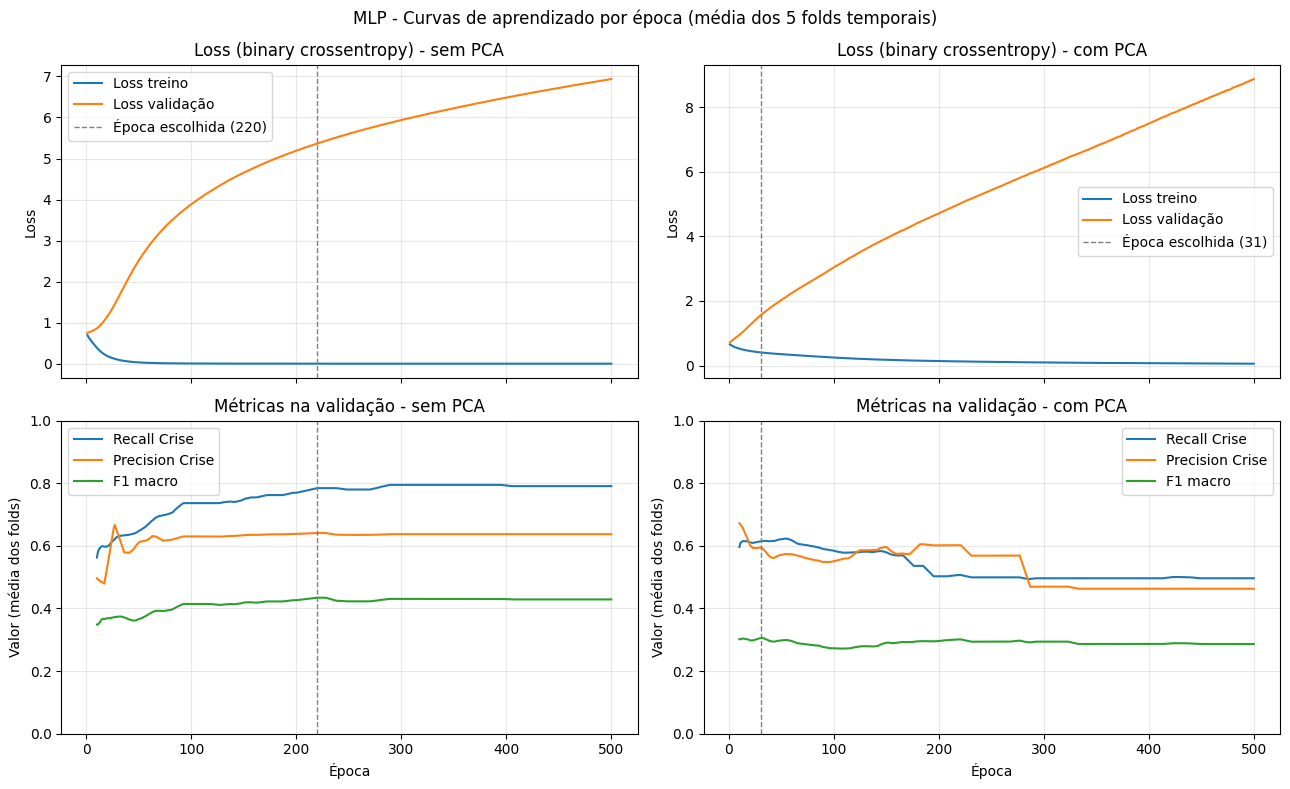

In [64]:
# Redesenha as curvas de 500 épocas já calculadas na célula anterior, sem treinar novamente
plot_curvas_epoca(curvas_mlp_no_pca, curvas_mlp_pca)

MLP Keras - Comparação de arquiteturas

c:\Users\vitor.boos\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\vitor.boos\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\vitor.boos\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the

sem PCA | 16: época 224


c:\Users\vitor.boos\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\vitor.boos\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\vitor.boos\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the

sem PCA | 32: época 299


c:\Users\vitor.boos\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\vitor.boos\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\vitor.boos\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the

...

com PCA | 64-32: época 31


c:\Users\vitor.boos\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\vitor.boos\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\vitor.boos\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the

com PCA | 128-64: época 25


c:\Users\vitor.boos\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


,cenario,arquitetura,parametros,epoca_escolhida,f1_macro_val,recall_crise_val,precision_crise_val,f1_desvio_folds
0,sem PCA,16,257,224,0.4340,0.8101,0.6422,0.2061
1,sem PCA,32,513,299,0.4329,0.8164,0.6302,0.2063
2,sem PCA,32-16,1025,248,0.4466,0.8255,0.6439,0.2324
3,sem PCA,64-32,3073,220,0.4344,0.7844,0.6410,0.1989
4,sem PCA,128-64,10241,185,0.4535,0.8130,0.6390,0.2215
5,com PCA,16,81,84,0.3538,0.7333,0.6162,0.1904
6,com PCA,32,161,10,0.3757,0.8212,0.5732,0.0881
7,com PCA,32-16,673,229,0.3025,0.5963,0.5884,0.1075
8,com PCA,64-32,2369,31,0.3065,0.6153,0.5941,0.1414
9,com PCA,128-64,8833,25,0.3096,0.6354,0.5853,0.1439


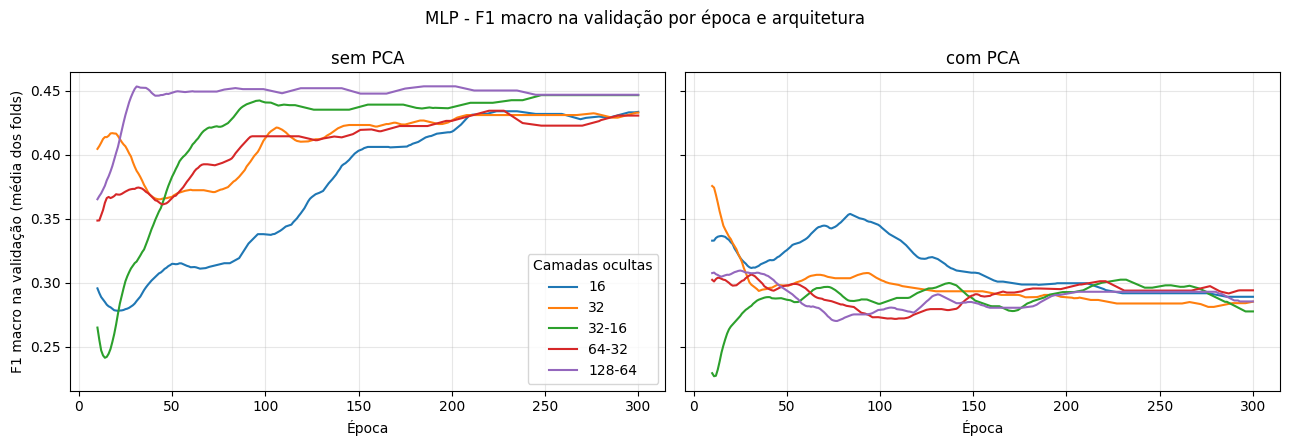

In [61]:
# =====================================================
# COMPARAÇÃO DE ARQUITETURAS
# =====================================================
# Conjunto fechado de arquiteturas, da menor para a maior capacidade.
# 300 épocas: nas curvas da arquitetura inicial (64 -> 32), nenhuma métrica melhora depois disso.

ARQUITETURAS = {
    "16": (16,),
    "32": (32,),
    "32-16": (32, 16),
    "64-32": (64, 32),
    "128-64": (128, 64)
}
EPOCAS_ARQUITETURAS = 300

curvas_arquiteturas = {}
linhas = []

for versao, X_arq, y_arq in [
    ("sem PCA", X_train_scaled, y_train_no_pca),
    ("com PCA", X_train_pca, y_train_pca)
]:
    for nome, camadas in ARQUITETURAS.items():
        curvas = curvas_por_epoca(X_arq, y_arq, camadas, epocas=EPOCAS_ARQUITETURAS)
        curvas_arquiteturas[(versao, nome)] = curvas

        e = epoca_escolhida(curvas)
        linhas.append({
            "cenario": versao,
            "arquitetura": nome,
            "parametros": criar_mlp(np.asarray(X_arq).shape[1], camadas).count_params(),
            "epoca_escolhida": e,
            "f1_macro_val": suavizar(curvas["f1_macro"].mean(axis=0))[e - 1],
            "recall_crise_val": suavizar(curvas["recall"].mean(axis=0))[e - 1],
            "precision_crise_val": suavizar(curvas["precision"].mean(axis=0))[e - 1],
            "f1_desvio_folds": curvas["f1_macro"][:, e - 1].std()
        })
        print(f"{versao} | {nome}: época {e}")

df_arquiteturas = pd.DataFrame(linhas).round(4)
display(df_arquiteturas)

# ===== FIGURA PARA O DOCUMENTO: F1 macro de validação por época, uma linha por arquitetura =====
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
epocas = np.arange(1, EPOCAS_ARQUITETURAS + 1)

for ax, versao in zip(axes, ["sem PCA", "com PCA"]):
    for nome in ARQUITETURAS:
        curvas = curvas_arquiteturas[(versao, nome)]
        ax.plot(epocas, suavizar(curvas["f1_macro"].mean(axis=0)), label=nome)
    ax.set_title(versao)
    ax.set_xlabel("Época")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("F1 macro na validação (média dos folds)")
axes[0].legend(title="Camadas ocultas")
fig.suptitle("MLP - F1 macro na validação por época e arquitetura")
plt.tight_layout()
plt.show()

Tabela Comparativa: Sem PCA x Com PCA

In [62]:
import pandas as pd
import numpy as np

df_resultados = pd.DataFrame(resultados)

# Separa o nome base do modelo (tira o sufixo "(sem PCA)" / "(PCA)")
df_resultados["modelo_base"] = df_resultados["modelo"].str.replace(
    r"\s*\((sem PCA|PCA)\)", "", regex=True
)
df_resultados["versao"] = df_resultados["modelo"].apply(
    lambda x: "sem_pca" if "sem PCA" in x else "pca"
)

metricas = ["accuracy", "precision", "recall", "f1_macro", "tempo_treino_s"]

ordem_modelos = df_resultados["modelo_base"].drop_duplicates().tolist()

tabela = df_resultados.pivot(
    index="modelo_base",
    columns="versao",
    values=metricas
).reindex(ordem_modelos)

linhas = []

for modelo_base in tabela.index:
    linha = {"Modelo": modelo_base}

    for metrica in metricas:
        sem_pca = tabela.loc[modelo_base, (metrica, "sem_pca")]
        com_pca = tabela.loc[modelo_base, (metrica, "pca")]

        nome_col = metrica.replace("_macro", "").replace("_s", "").capitalize()

        linha[f"{nome_col} (sem PCA)"] = round(sem_pca, 4)
        linha[f"{nome_col} (com PCA)"] = round(com_pca, 4)

        if metrica == "tempo_treino_s":
            # Diferença absoluta em segundos (percentual não faz sentido
            # quando o tempo base é muito próximo de zero)
            variacao = com_pca - sem_pca
            linha[f"{nome_col} (Δ s)"] = round(variacao, 4)
        else:
            if pd.notna(sem_pca) and sem_pca != 0:
                variacao = ((com_pca - sem_pca) / sem_pca) * 100
            else:
                variacao = np.nan
            linha[f"{nome_col} (Δ %)"] = round(variacao, 4)

    linhas.append(linha)

df_comparativo = pd.DataFrame(linhas).set_index("Modelo")

colunas_delta = [c for c in df_comparativo.columns if "Δ" in c]
colunas_delta_tempo = [c for c in colunas_delta if "Tempo" in c]
colunas_delta_metricas = [c for c in colunas_delta if c not in colunas_delta_tempo]
colunas_valores = [c for c in df_comparativo.columns if c not in colunas_delta]

def cor_variacao(coluna, inverter=False):
    def aplicar(val):
        if isinstance(val, (int, float)) and not pd.isna(val):
            positivo = val < 0 if inverter else val > 0
            negativo = val > 0 if inverter else val < 0
            if positivo:
                return "color: green; font-weight: bold"
            elif negativo:
                return "color: red; font-weight: bold"
        return ""
    return coluna.map(aplicar)

display(
    df_comparativo.style
    .format("{:.4f}", subset=colunas_valores)
    .format("{:+.4f}%", subset=colunas_delta_metricas)
    .format("{:+.4f}s", subset=colunas_delta_tempo)
    .apply(cor_variacao, subset=colunas_delta_metricas)
    .apply(cor_variacao, inverter=True, subset=colunas_delta_tempo)
)

,Accuracy (sem PCA),Accuracy (com PCA),Accuracy (Δ %),Precision (sem PCA),Precision (com PCA),Precision (Δ %),Recall (sem PCA),Recall (com PCA),Recall (Δ %),F1 (sem PCA),F1 (com PCA),F1 (Δ %),Tempo_treino (sem PCA),Tempo_treino (com PCA),Tempo_treino (Δ s)
Modelo,,,,,,,,,,,,,,,
Decision Tree,0.5878,0.5344,-9.0909%,0.5719,0.5152,-9.9248%,0.5842,0.5177,-11.3802%,0.5633,0.5048,-10.3901%,42.2024,1.2802,-40.9222s
KNN,0.5725,0.5878,+2.6667%,0.5097,0.6551,+28.5435%,0.5102,0.6683,+30.9908%,0.5094,0.5866,+15.1645%,1.3128,0.9387,-0.3741s
Random Forest,0.6107,0.5954,-2.5000%,0.5869,0.6193,+5.5177%,0.6007,0.6387,+6.3343%,0.5826,0.5876,+0.8697%,74.3414,64.6143,-9.7271s
Voting Ensemble,0.6031,0.5649,-6.3291%,0.5818,0.5951,+2.2827%,0.5952,0.6098,+2.4463%,0.5762,0.5583,-3.1000%,3.8913,3.5778,-0.3136s
MLP Keras,0.4885,0.6336,+29.6875%,0.5853,0.5927,+1.2646%,0.5828,0.6032,+3.4881%,0.4884,0.5938,+21.5728%,10.1919,9.0502,-1.1417s
